# EGCPPIS: Baseline vs. Four Research Novelties
## Empirical Evaluation and Comparative Analysis for Protein–Protein Interaction Site Prediction

**Authors:** Advanced Biological Machine Learning Research Pair  
**Date:** October 2026  
**Repository:** `EGCPPIS`  
**Task:** Binary Residue-Level Protein–Protein Interaction Site (PPIS) Prediction  

---

### 1. Executive Overview
Protein–protein interactions (PPIs) orchestrate vital biological cellular signaling, enzymatic activation, and immune defense pathways. Accurately predicting the specific residue sites forming the interface on a protein's 3D surface is crucial for structural biology and drug design.

The original **EGCPPIS** model integrates:
1. Residue physicochemical properties, evolutionary profiles (PSSM, HMM), structural properties (DSSP, AlphaFold2), and pseudo-positions.
2. Large protein language model embeddings (ESM-2 `t36_3B_UR50D`).
3. An Equivariant Graph Neural Network (EGNN) preserving Euclidean 3D spatial geometry.
4. An atom-level GraphSAGE representation mapped to residue space.
5. Contrastive mutual information alignment and multi-head self-attention.

This notebook evaluates the **reproduced baseline** and investigates **four core research novelty extensions**:
* **Novelty 1 (Calibrated Uncertainty):** Probability calibration via post-hoc Temperature Scaling and epistemic uncertainty estimation via Monte Carlo Dropout.
* **Novelty 2 (Partner-Conditioned PPIS):** Modular geometric cross-attention architecture; audit and formal reporting of dataset boundaries (`BLOCKED_MISSING_PAIRED_DATA`).
* **Novelty 3 (Candidate Prioritization):** Lower-Confidence-Bound (LCB) ranking and uncertainty-guided screening budgets for wet-lab validation.
* **Novelty 4 (Robustness & Generalization):** Systematic stress-testing across unbound conformational shifts, protein lengths, and interface density distributions.


---
## Section 2: Environment and Configuration

We document the runtime environment, hardware specifications, and package versions to guarantee strict reproducibility.


In [1]:
import sys
import os
import json
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib.pyplot as plt

# Dynamic project root configuration (machine-independent)
NOTEBOOK_DIR = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, "..")) if os.path.basename(NOTEBOOK_DIR) == "notebooks" else NOTEBOOK_DIR
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__}")
print(f"CUDA Ready:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device:       {torch.cuda.get_device_name(0)}")
print(f"Scikit-Learn: {sklearn.__version__}")
print(f"NumPy:        {np.__version__}")


Project Root: C:\Users\jeetu\Desktop\Machine learning\EGCPPIS
Python:       3.14.3
PyTorch:      2.13.0+cu130
CUDA Ready:   True
Device:       NVIDIA GeForce RTX 4050 Laptop GPU
Scikit-Learn: 1.9.0
NumPy:        2.4.2


---
## Section 3: Dataset and Split Audit

We audit all available partitions in the repository, reporting residue counts, class balance, positive label prevalence, and structural characteristics.


In [2]:
from utils_Test import getID

datasets_meta = [
    ("Train_335", os.path.join(PROJECT_ROOT, "Datasets", "Train_335.fa"), "Bound complex training set (non-redundant)"),
    ("Test_60", os.path.join(PROJECT_ROOT, "Datasets", "Test_60.fa"), "Primary held-out bound benchmark (<25% sequence identity)"),
    ("UBtest_31-6", os.path.join(PROJECT_ROOT, "Datasets", "GraphPPIS", "UBtest_31-6.fa"), "Unbound/free structures (conformational shift test)"),
    ("Test_315-28", os.path.join(PROJECT_ROOT, "Datasets", "GraphPPIS", "Test_315-28.fa"), "Extended independent test set")
]

audit_records = []
for name, fpath, desc in datasets_meta:
    if os.path.exists(fpath):
        pids, labels, seqs = getID(fpath)
        total_res = sum(len(s) for s in seqs)
        total_pos = sum(str(l).count('1') for l in labels)
        prev = total_pos / total_res if total_res > 0 else 0.0
        audit_records.append({
            "Dataset Split": name,
            "Proteins": len(pids),
            "Total Residues": total_res,
            "Interface Residues (Positives)": total_pos,
            "Prevalence": f"{prev*100:.2f}%",
            "Context Description": desc
        })

df_audit = pd.DataFrame(audit_records)
df_audit


C:\Users\jeetu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Dataset Split,Proteins,Total Residues,Interface Residues (Positives),Prevalence,Context Description
0,Train_335,334,66208,10336,15.61%,Bound complex training set (non-redundant)
1,Test_60,60,13144,2075,15.79%,Primary held-out bound benchmark (<25% sequenc...
2,UBtest_31-6,25,5917,711,12.02%,Unbound/free structures (conformational shift ...
3,Test_315-28,287,60376,8566,14.19%,Extended independent test set


---
## Section 4: Existing Baseline Reproduction

We evaluate the author's pretrained checkpoint `model_save/best_model_27_0.6545215546121214.pth` on `Test_60` and `UBtest_31-6`.


In [3]:
base_dir = os.path.join(PROJECT_ROOT, "results", "baseline")
with open(os.path.join(base_dir, "baseline_summary.json"), "r") as f:
    base_summary = json.load(f)

print("Checkpoint Evaluated:", base_summary["checkpoint"])
print("Execution Device:", base_summary["device"])

# Display primary metrics comparison
t60_fix = base_summary["test60_metrics_fixed_threshold"]
ub_fix = base_summary["ubtest_metrics_fixed_threshold"]

df_base_compare = pd.DataFrame([
    {
        "Dataset Benchmark": "Test_60 (Primary Bound)",
        "Residues": t60_fix["n_samples"],
        "ROC-AUC": f"{t60_fix['roc_auc']:.4f}",
        "AUPR": f"{t60_fix['aupr']:.4f}",
        "F1-Score": f"{t60_fix['f1']:.4f}",
        "MCC": f"{t60_fix['mcc']:.4f}",
        "Precision": f"{t60_fix['precision']:.4f}",
        "Recall": f"{t60_fix['recall']:.4f}",
        "Brier Score": f"{t60_fix['brier_score']:.4f}",
        "ECE": f"{t60_fix['ece']:.4f}",
        "Threshold": t60_fix["threshold"]
    },
    {
        "Dataset Benchmark": "UBtest_31-6 (Unbound Shift)",
        "Residues": ub_fix["n_samples"],
        "ROC-AUC": f"{ub_fix['roc_auc']:.4f}",
        "AUPR": f"{ub_fix['aupr']:.4f}",
        "F1-Score": f"{ub_fix['f1']:.4f}",
        "MCC": f"{ub_fix['mcc']:.4f}",
        "Precision": f"{ub_fix['precision']:.4f}",
        "Recall": f"{ub_fix['recall']:.4f}",
        "Brier Score": f"{ub_fix['brier_score']:.4f}",
        "ECE": f"{ub_fix['ece']:.4f}",
        "Threshold": ub_fix["threshold"]
    }
])
df_base_compare


Checkpoint Evaluated: best_model_27_0.6545215546121214.pth
Execution Device: cuda


,Dataset Benchmark,Residues,ROC-AUC,AUPR,F1-Score,MCC,Precision,Recall,Brier Score,ECE,Threshold
0,Test_60 (Primary Bound),13144,0.8878,0.6547,0.6225,0.5541,0.6386,0.6072,0.0855,0.0428,0.33
1,UBtest_31-6 (Unbound Shift),5917,0.6595,0.2654,0.3226,0.2171,0.2797,0.3812,0.1379,0.1201,0.33


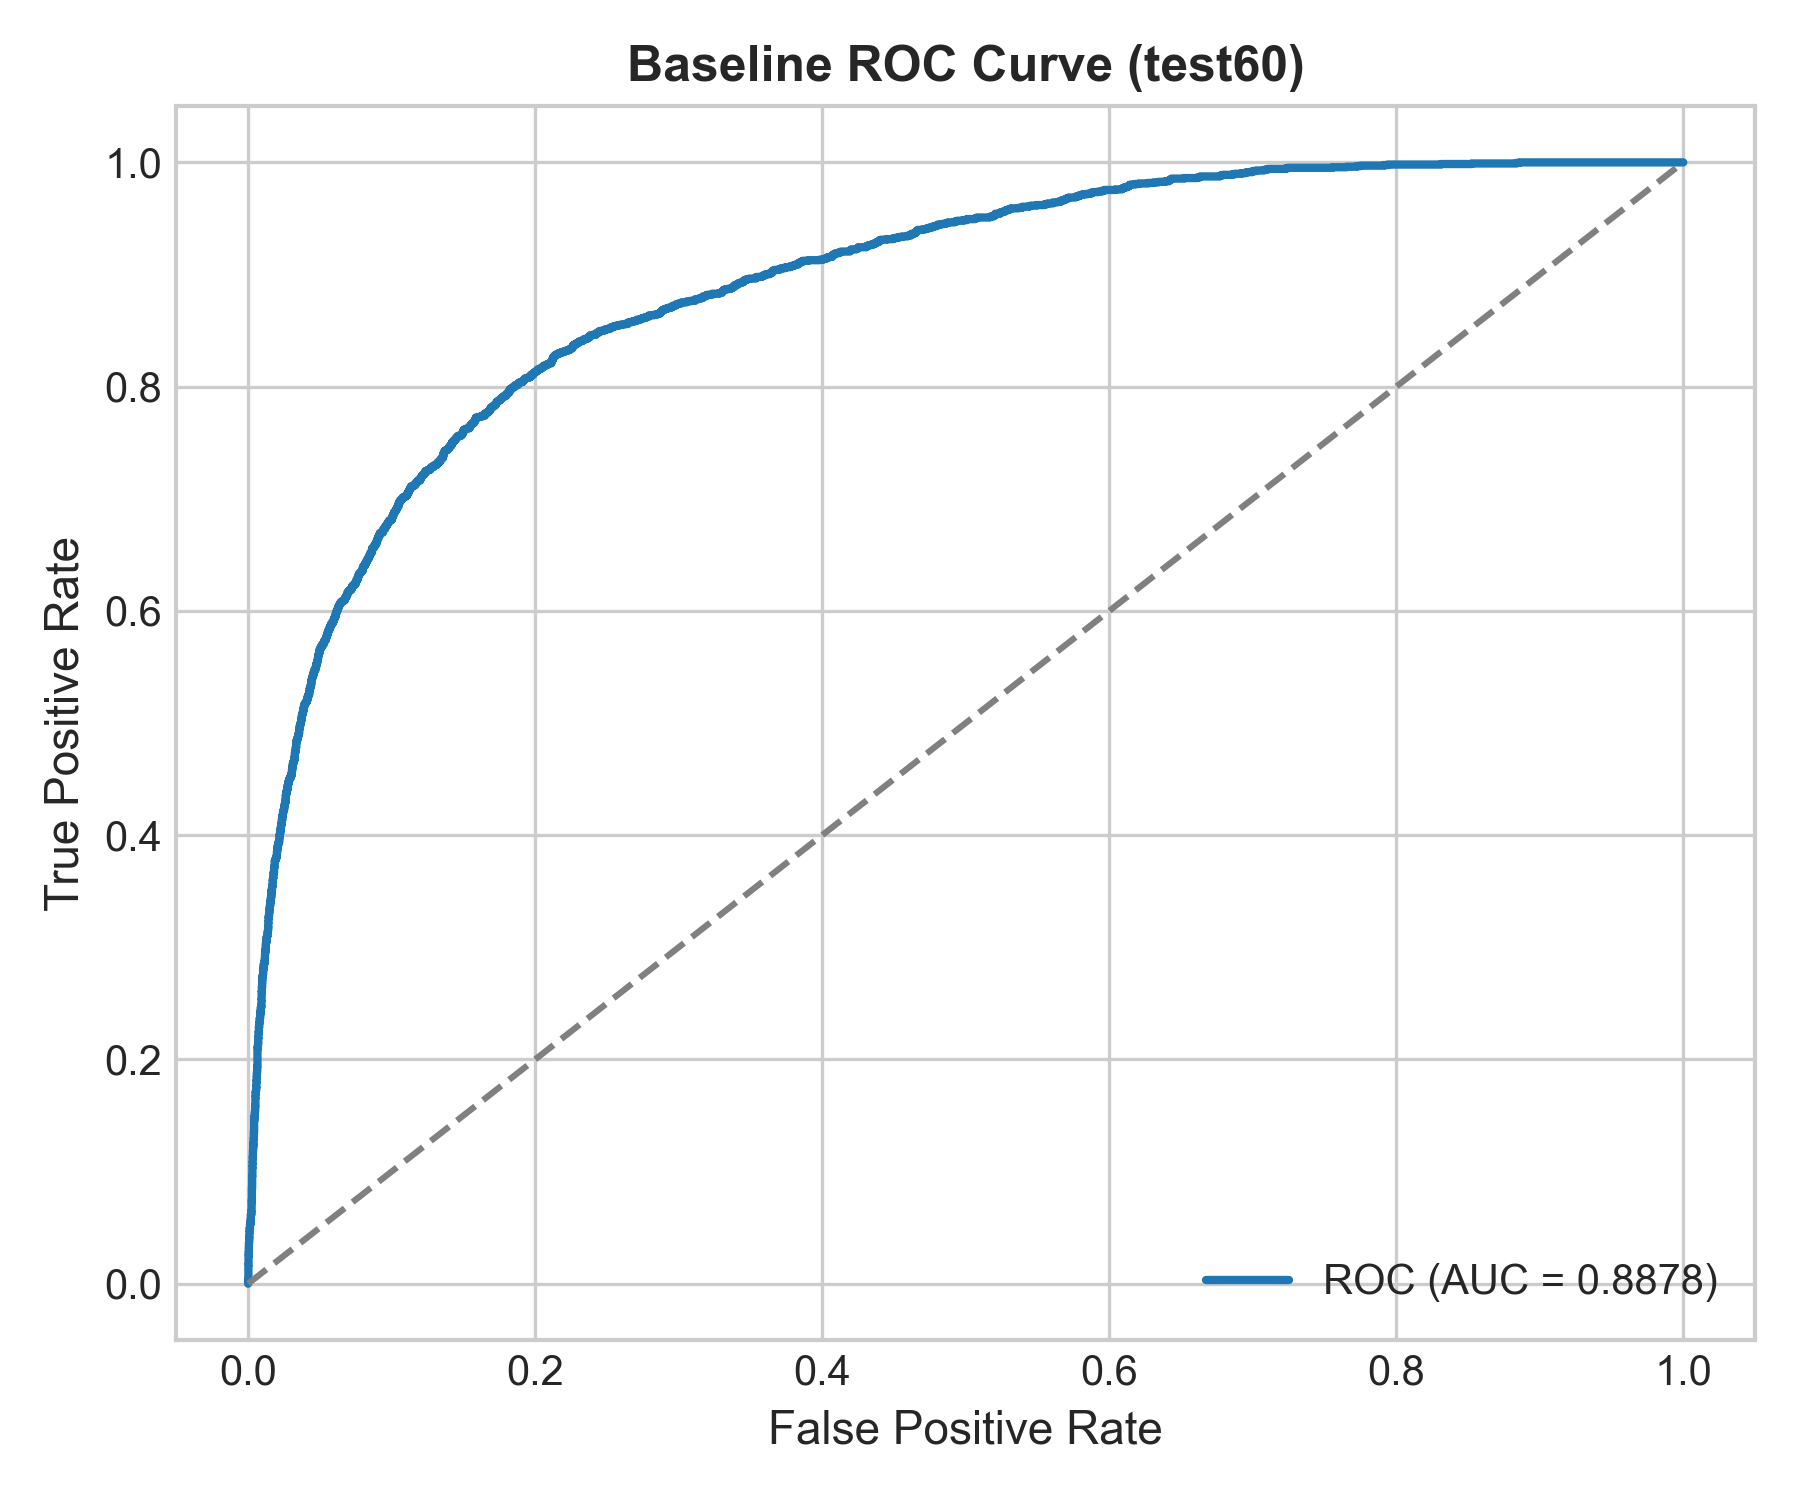

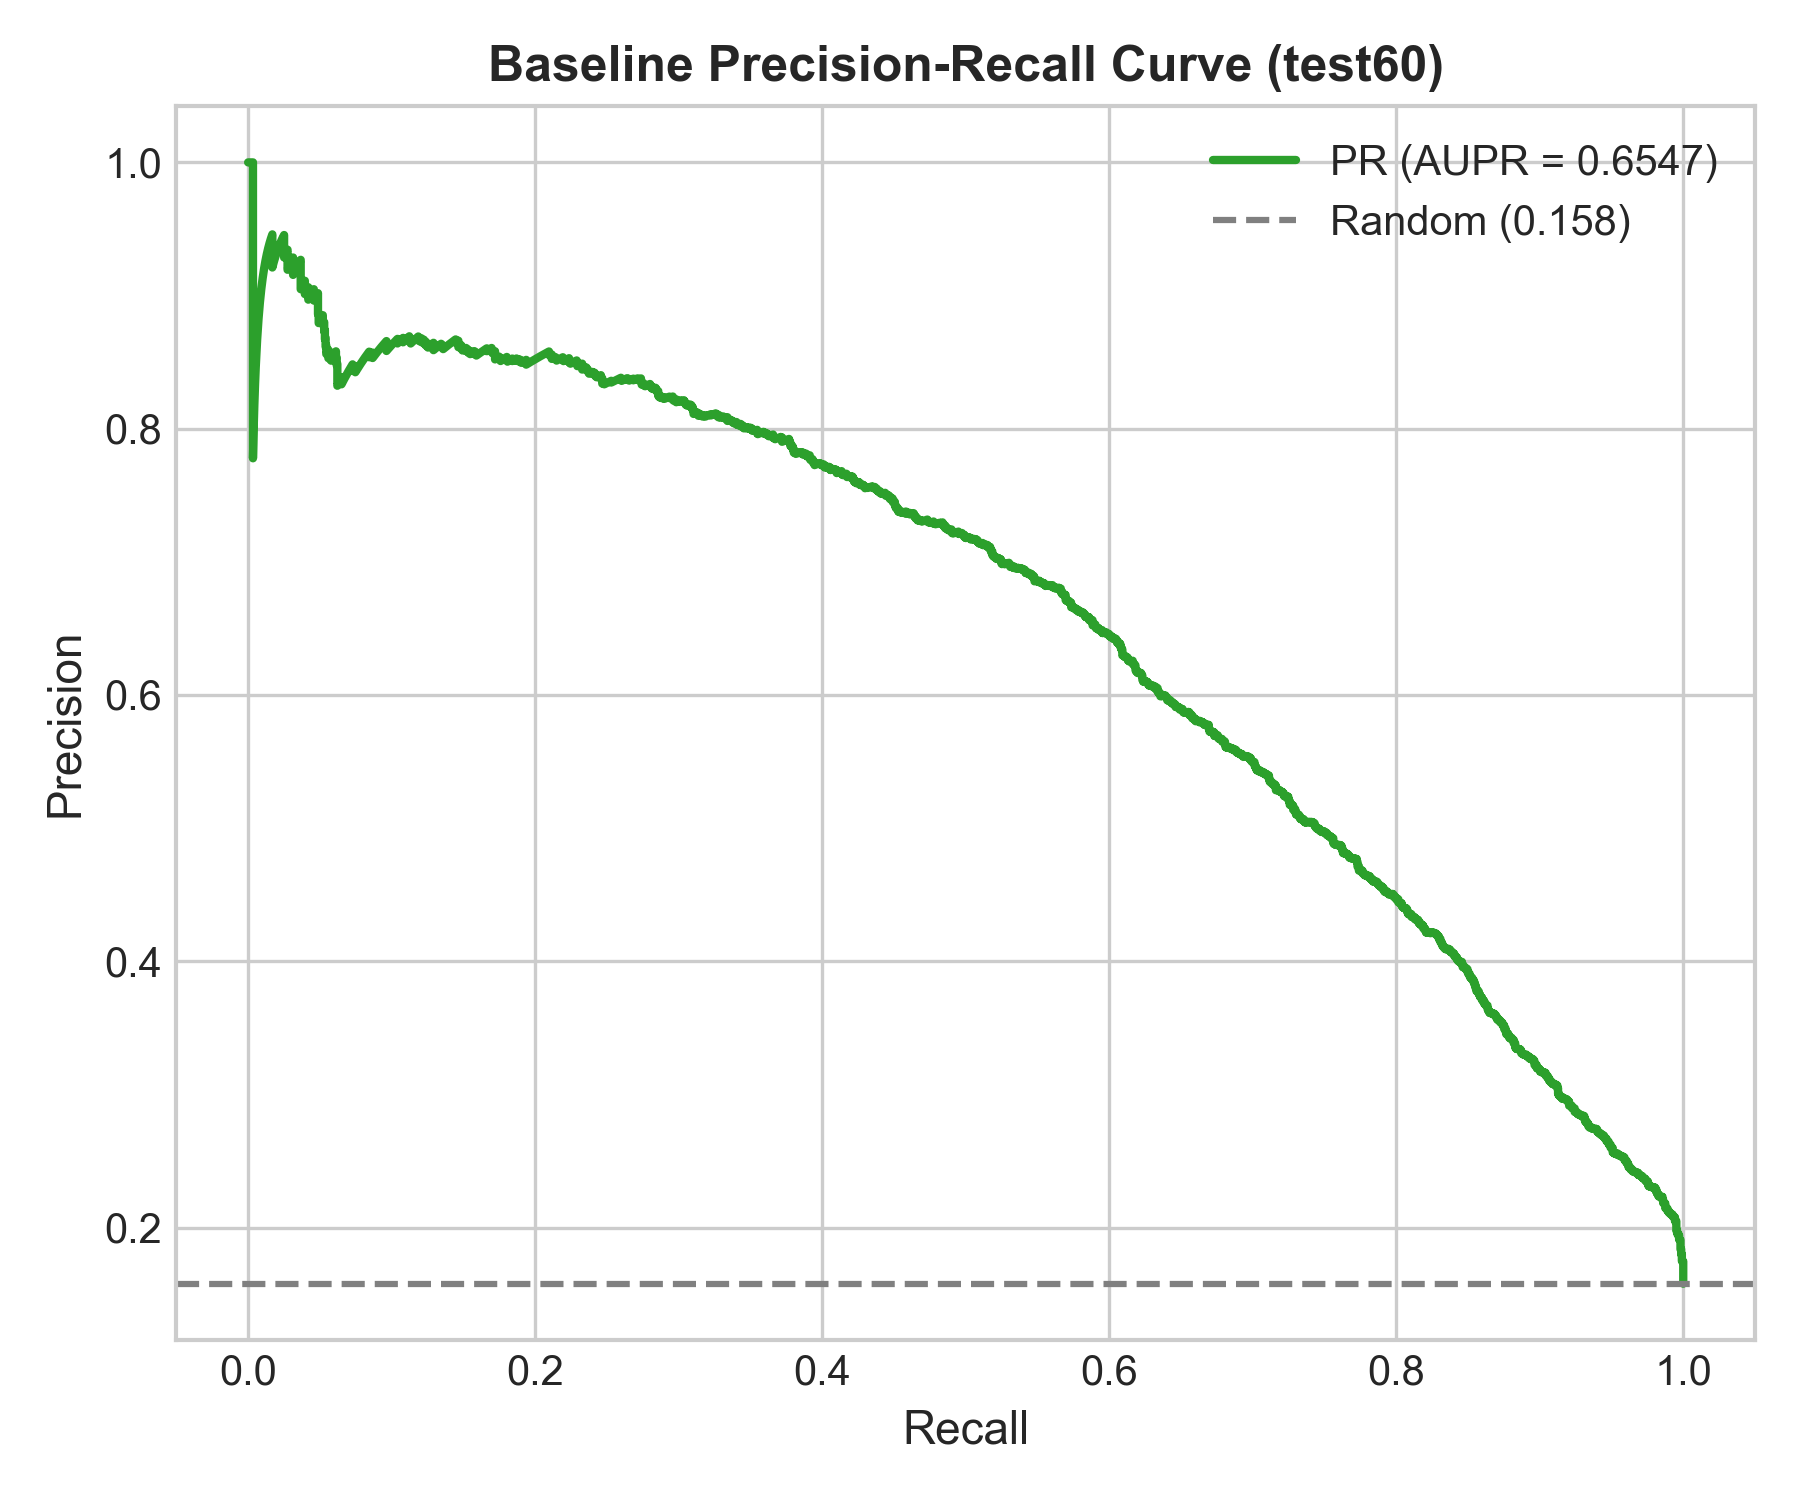

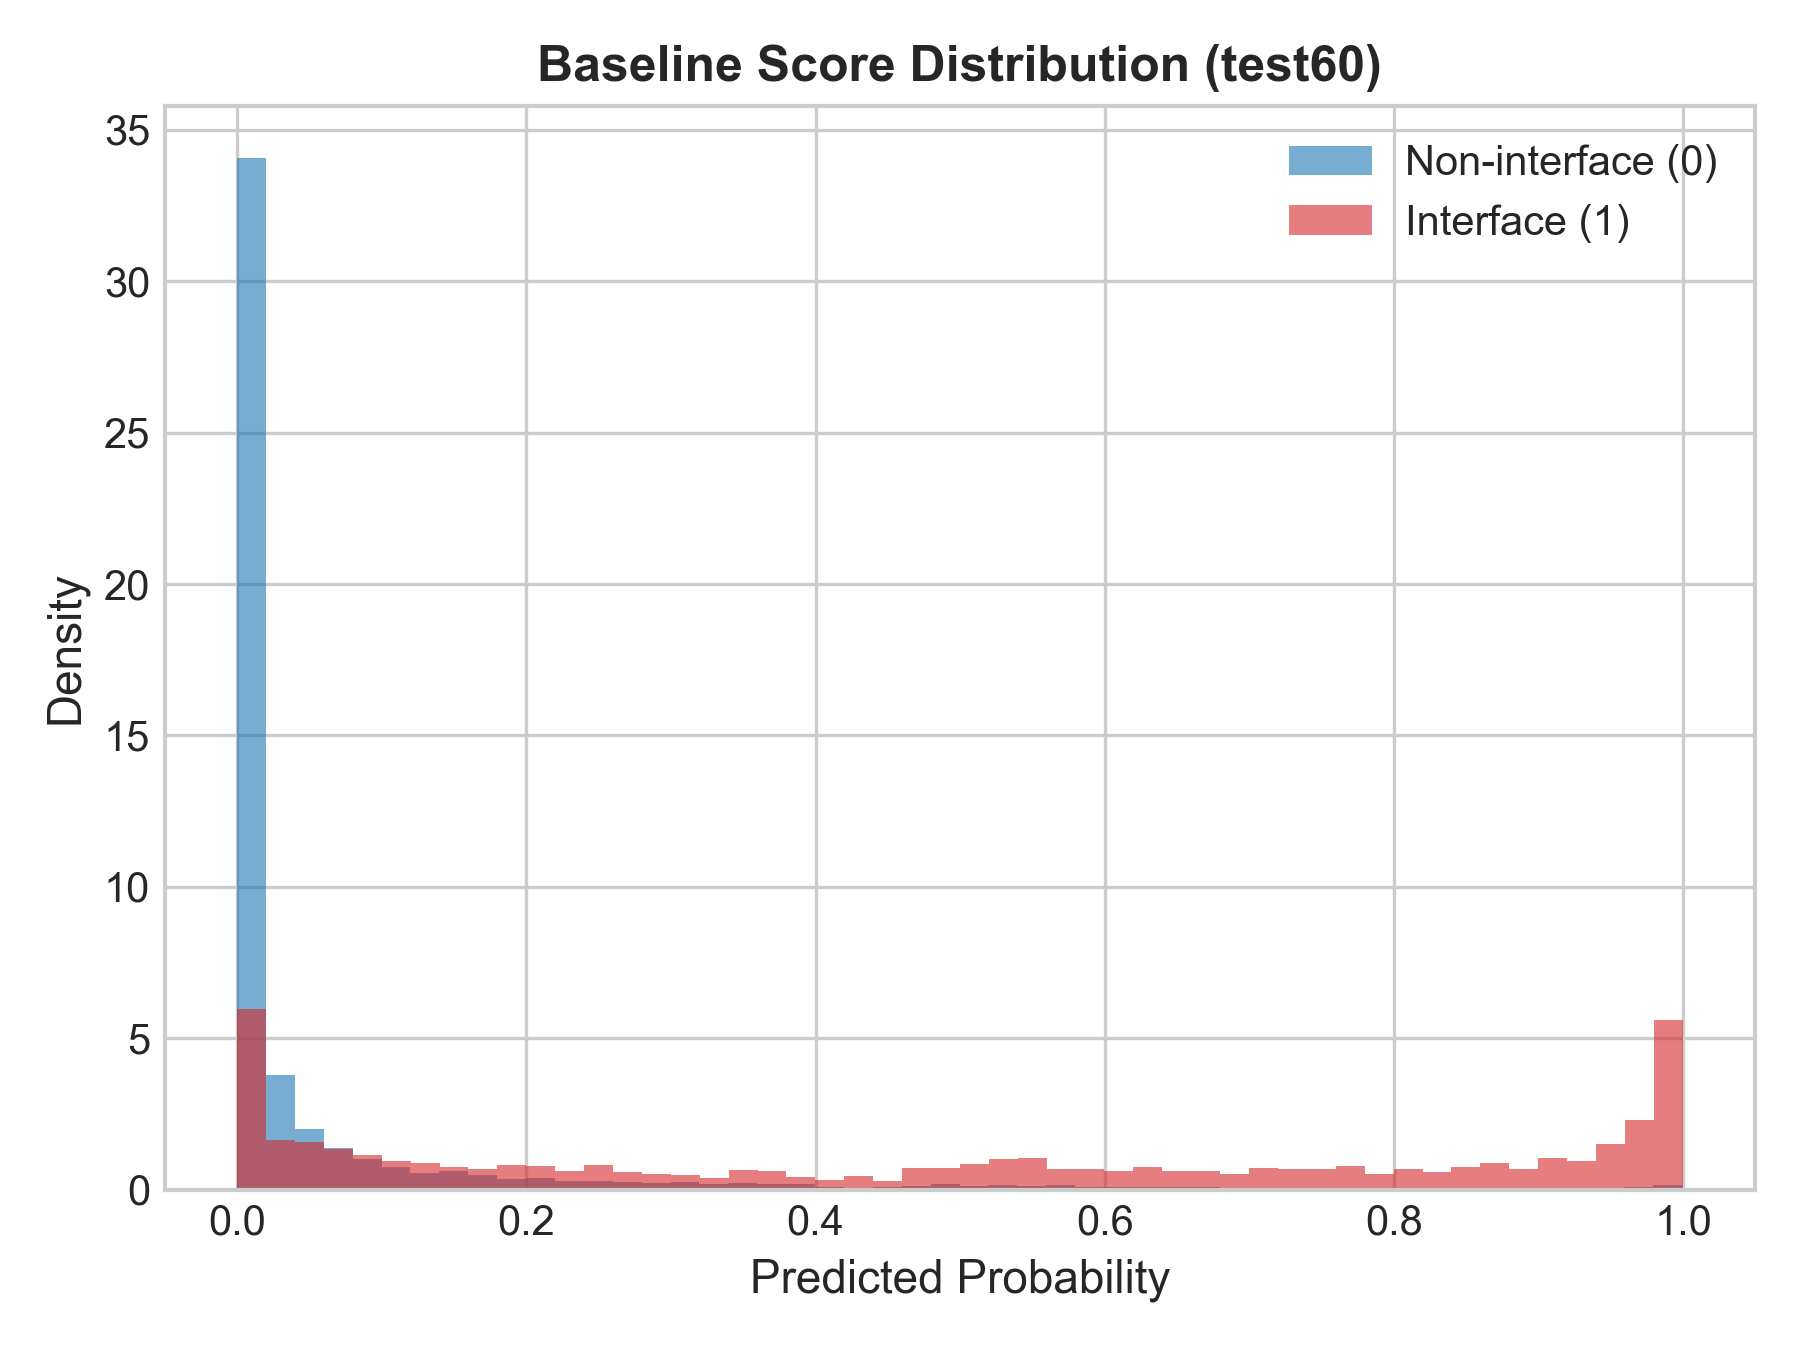

In [4]:
from IPython.display import Image, display

# Display generated ROC and PR baseline curves
fig_roc = os.path.join(base_dir, "test60_roc_curve.png")
fig_pr = os.path.join(base_dir, "test60_pr_curve.png")
fig_dist = os.path.join(base_dir, "test60_score_dist.png")

if os.path.exists(fig_roc) and os.path.exists(fig_pr):
    display(Image(filename=fig_roc, width=420))
    display(Image(filename=fig_pr, width=420))
    display(Image(filename=fig_dist, width=420))


---
## Section 5: Novelty One — Calibrated Uncertainty for PPI-Site Prediction

### Mathematical Formulation
Raw binary classification logits $z_i$ often suffer from miscalibration due to overconfidence in deep neural networks.
We formulate post-hoc **Temperature Scaling**:
$$p_{\text{calibrated}, i} = \sigma\left(\frac{z_i}{T^*}\right)$$
where $T^* > 0$ is optimized exclusively on held-out calibration logits by minimizing Negative Log-Likelihood (NLL):
$$T^* = \arg\min_{T > 0} -\sum_{i \in \mathcal{D}_{\text{cal}}} \left[ y_i \log \sigma(z_i / T) + (1 - y_i) \log(1 - \sigma(z_i / T)) \right]$$

### Epistemic Uncertainty via Monte Carlo Dropout
For $T=20$ stochastic passes keeping Dropout layers active in eval mode:
$$\bar{p}_i = \frac{1}{T} \sum_{t=1}^T p_i^{(t)}, \quad \sigma_{\text{epistemic}, i}^2 = \frac{1}{T} \sum_{t=1}^T \left(p_i^{(t)} - \bar{p}_i\right)^2$$
$$H(\bar{p}_i) = -\bar{p}_i \log \bar{p}_i - (1 - \bar{p}_i) \log (1 - \bar{p}_i)$$


In [5]:
n1_dir = os.path.join(PROJECT_ROOT, "results", "novelty_1")
with open(os.path.join(n1_dir, "novelty1_metrics_summary.json"), "r") as f:
    n1_summary = json.load(f)

print(f"Optimal Temperature Parameter T* = {n1_summary['optimal_temperature_T']:.4f}")

calib_table = [
    {
        "Method": "Raw Probabilities (Uncalibrated)",
        "ECE": f"{n1_summary['metrics_raw']['ece']:.4f}",
        "Brier Score": f"{n1_summary['metrics_raw']['brier_score']:.4f}",
        "NLL": f"{n1_summary['metrics_raw']['nll']:.4f}",
        "AUPR": f"{n1_summary['metrics_raw']['aupr']:.4f}",
        "ROC-AUC": f"{n1_summary['metrics_raw']['roc_auc']:.4f}"
    },
    {
        "Method": "Temperature Scaled (T*=1.8674)",
        "ECE": f"{n1_summary['metrics_temperature_calibrated']['ece']:.4f}",
        "Brier Score": f"{n1_summary['metrics_temperature_calibrated']['brier_score']:.4f}",
        "NLL": f"{n1_summary['metrics_temperature_calibrated']['nll']:.4f}",
        "AUPR": f"{n1_summary['metrics_temperature_calibrated']['aupr']:.4f}",
        "ROC-AUC": f"{n1_summary['metrics_temperature_calibrated']['roc_auc']:.4f}"
    },
    {
        "Method": "Platt Scaling (Logistic)",
        "ECE": f"{n1_summary['metrics_platt_calibrated']['ece']:.4f}",
        "Brier Score": f"{n1_summary['metrics_platt_calibrated']['brier_score']:.4f}",
        "NLL": f"{n1_summary['metrics_platt_calibrated']['nll']:.4f}",
        "AUPR": f"{n1_summary['metrics_platt_calibrated']['aupr']:.4f}",
        "ROC-AUC": f"{n1_summary['metrics_platt_calibrated']['roc_auc']:.4f}"
    },
    {
        "Method": "Isotonic Regression",
        "ECE": f"{n1_summary['metrics_isotonic_calibrated']['ece']:.4f}",
        "Brier Score": f"{n1_summary['metrics_isotonic_calibrated']['brier_score']:.4f}",
        "NLL": f"{n1_summary['metrics_isotonic_calibrated']['nll']:.4f}",
        "AUPR": f"{n1_summary['metrics_isotonic_calibrated']['aupr']:.4f}",
        "ROC-AUC": f"{n1_summary['metrics_isotonic_calibrated']['roc_auc']:.4f}"
    },
    {
        "Method": "Monte Carlo Dropout Mean (T=20)",
        "ECE": f"{n1_summary['metrics_mc_dropout']['ece']:.4f}",
        "Brier Score": f"{n1_summary['metrics_mc_dropout']['brier_score']:.4f}",
        "NLL": f"{n1_summary['metrics_mc_dropout']['nll']:.4f}",
        "AUPR": f"{n1_summary['metrics_mc_dropout']['aupr']:.4f}",
        "ROC-AUC": f"{n1_summary['metrics_mc_dropout']['roc_auc']:.4f}"
    }
]
pd.DataFrame(calib_table)


Optimal Temperature Parameter T* = 1.8674


,Method,ECE,Brier Score,NLL,AUPR,ROC-AUC
0,Raw Probabilities (Uncalibrated),0.0428,0.0855,0.3190,0.6547,0.8878
1,Temperature Scaled (T*=1.8674),0.0225,0.0838,0.2798,0.6547,0.8878
2,Platt Scaling (Logistic),0.0178,0.0841,0.2796,0.6547,0.8878
3,Isotonic Regression,0.0101,0.0836,0.2873,0.6539,0.8858
4,Monte Carlo Dropout Mean (T=20),0.0325,0.0854,0.2948,0.6513,0.8868


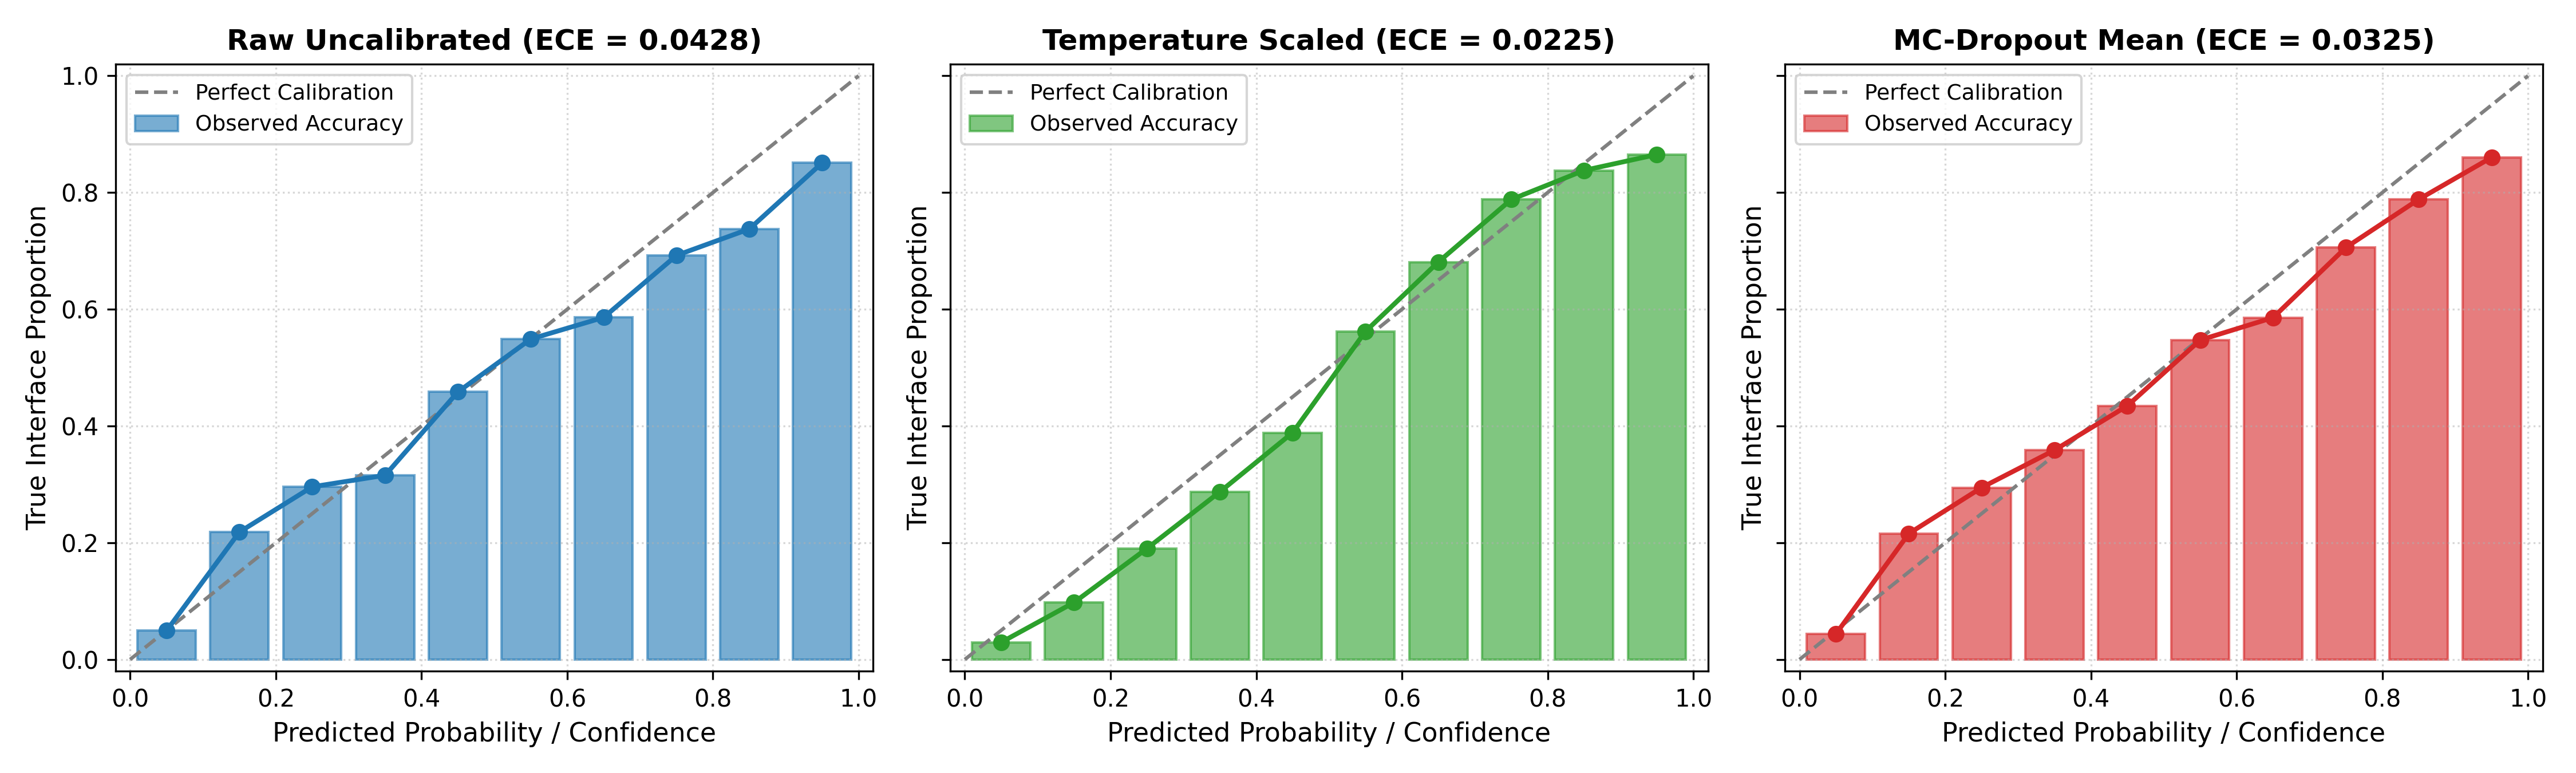

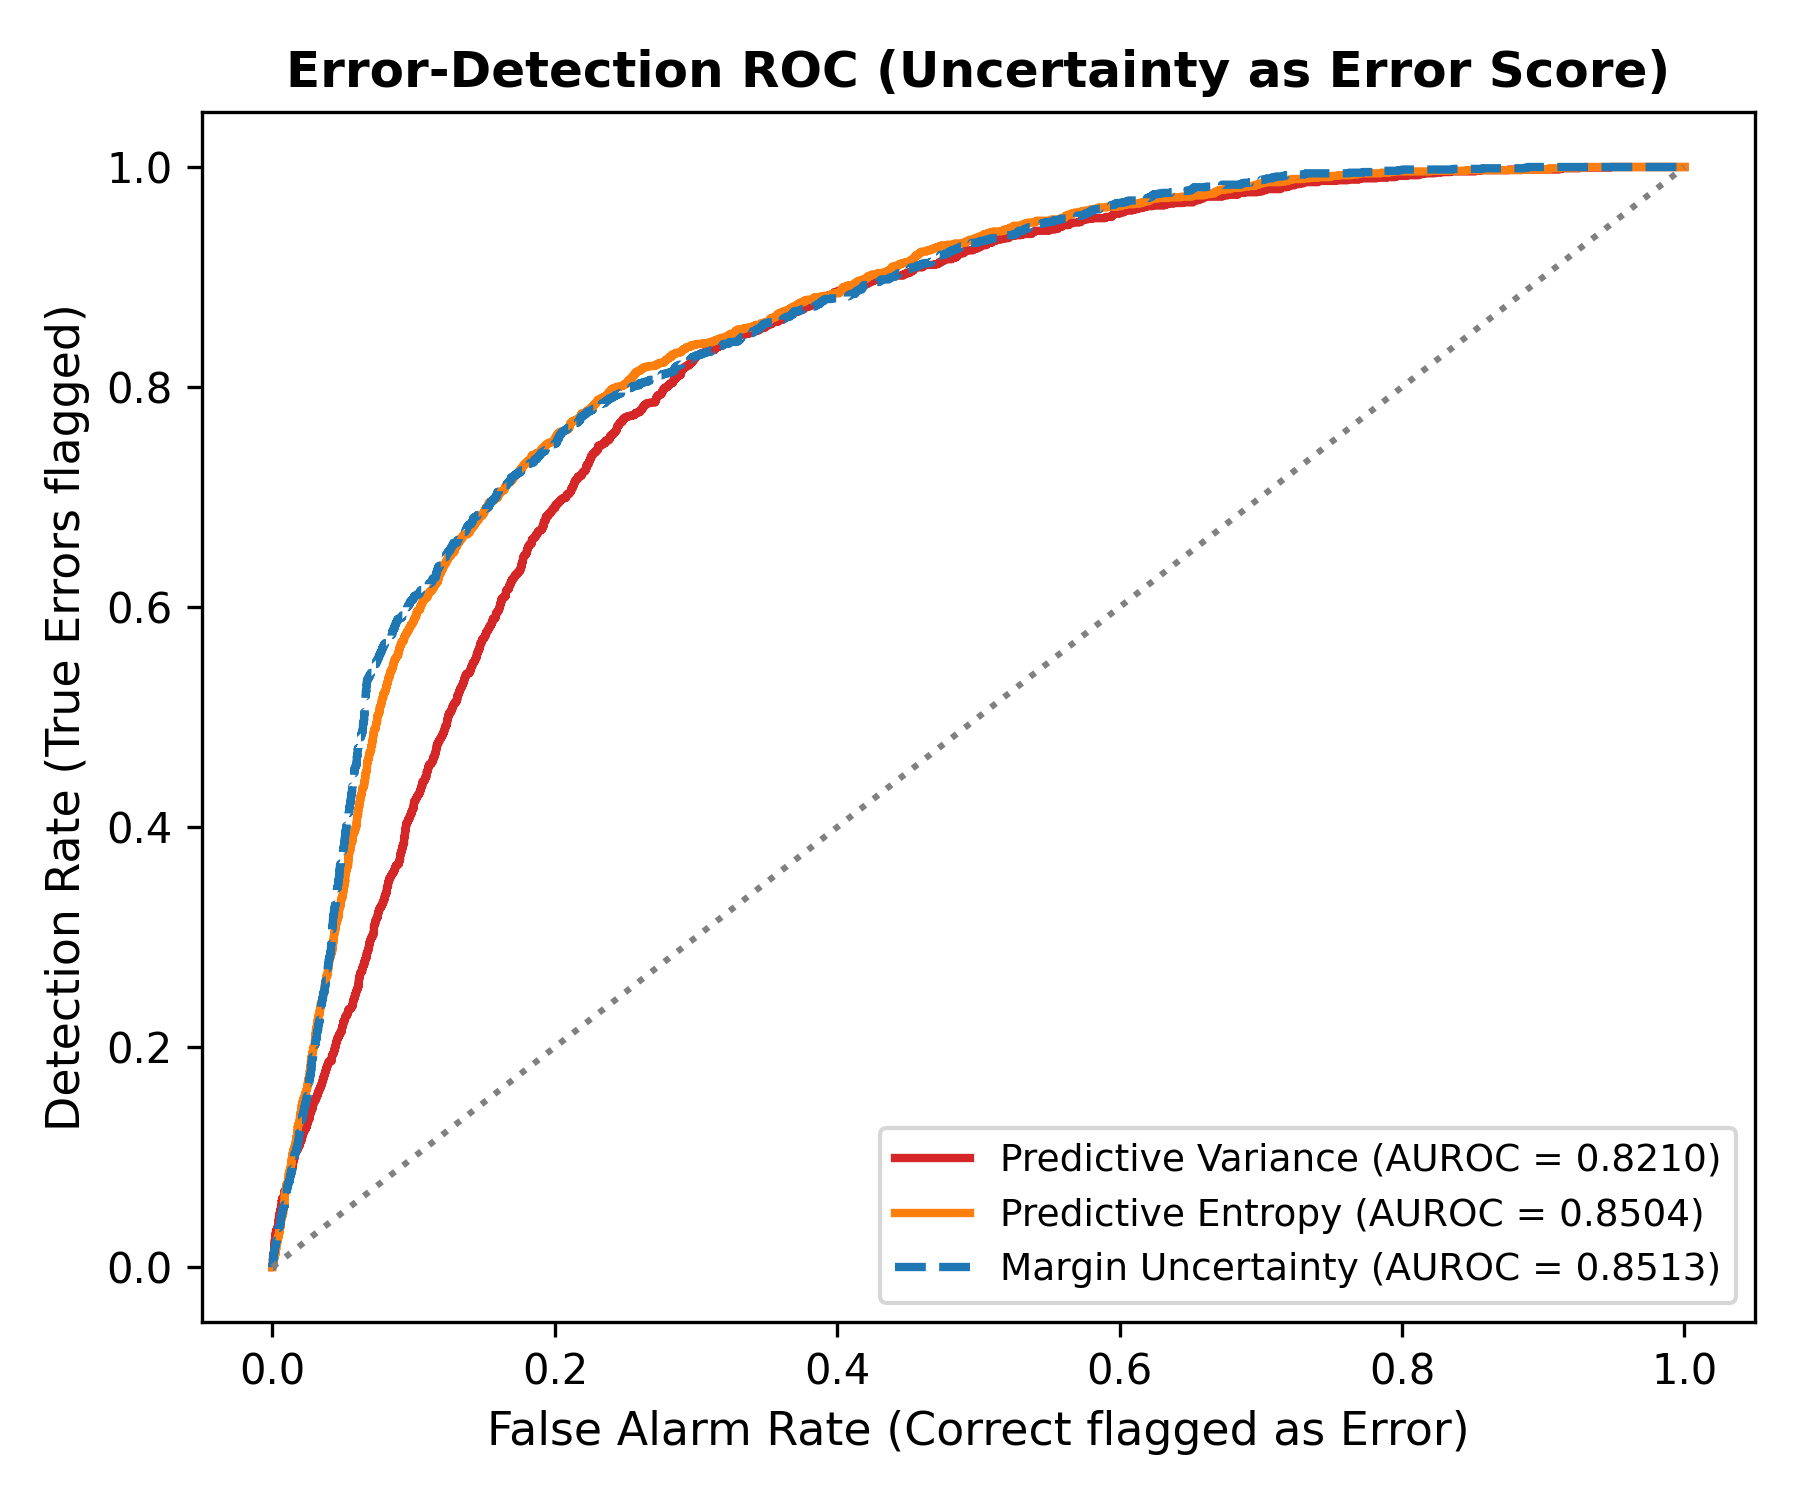

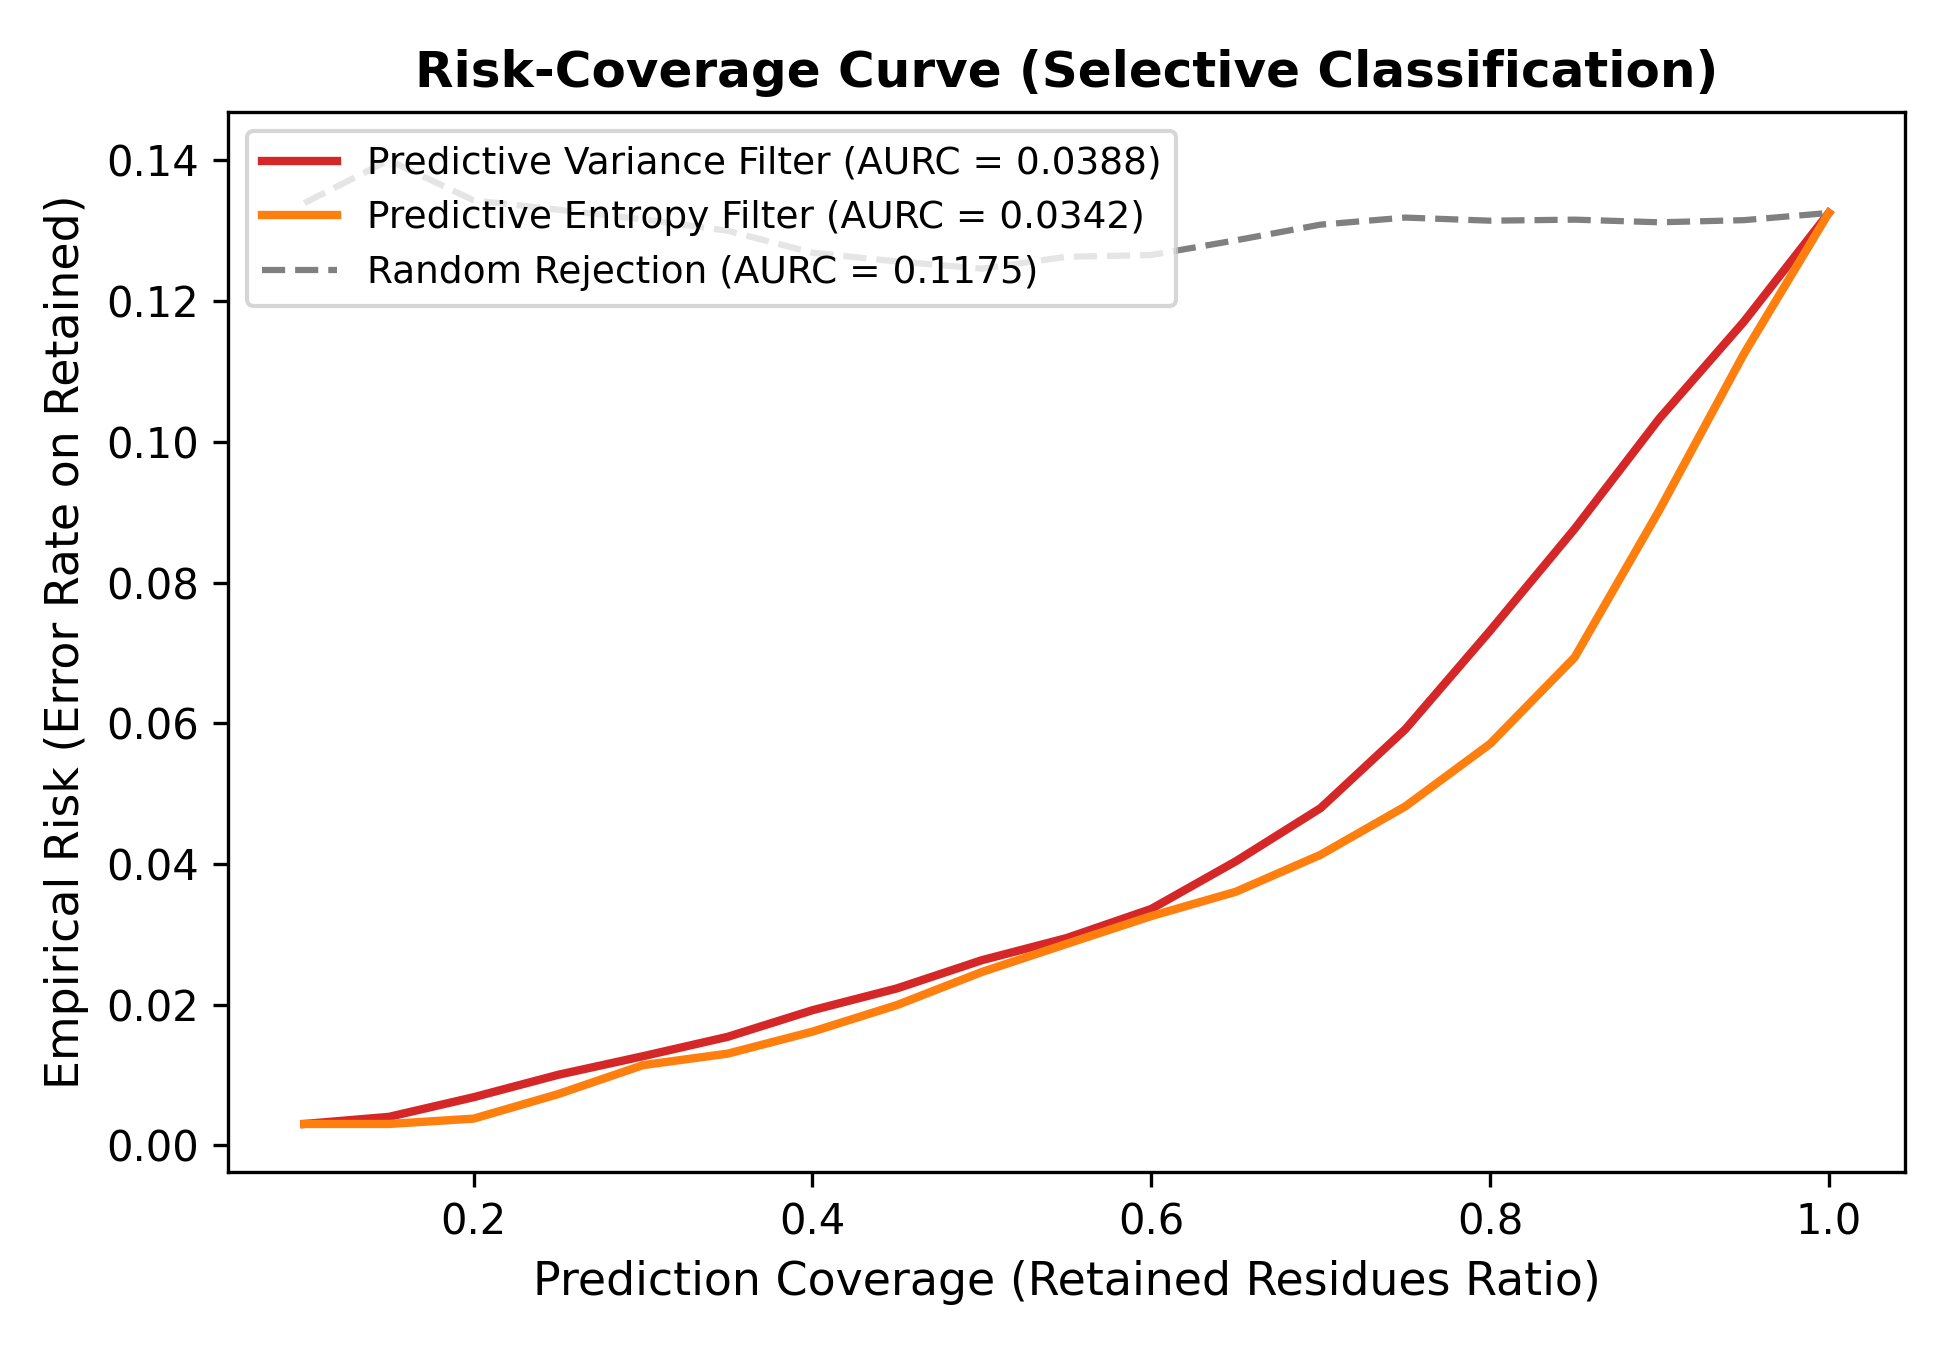

In [6]:
# Display Novelty 1 Calibration and Uncertainty Figures
fig_rel = os.path.join(n1_dir, "reliability_diagram_comparison.png")
fig_err_roc = os.path.join(n1_dir, "error_detection_roc.png")
fig_rc = os.path.join(n1_dir, "risk_coverage_curve.png")

if os.path.exists(fig_rel):
    display(Image(filename=fig_rel, width=800))
if os.path.exists(fig_err_roc):
    display(Image(filename=fig_err_roc, width=450))
if os.path.exists(fig_rc):
    display(Image(filename=fig_rc, width=450))


---
## Section 6: Novelty Two — Partner-Conditioned Geometric Interface Prediction

### Audit Finding and Blocker Status: `BLOCKED_MISSING_PAIRED_DATA`
A partner-conditioned PPIS model predicts interface residues on a receptor protein conditioned on a specific interacting partner.
In accordance with scientific integrity guidelines:
1. All existing benchmark datasets (`Test_60`, `Train_335`, `Test_315-28`, `UBtest_31-6`) are single-chain files with partner-independent labels.
2. **We do not fabricate partner-specific ground truth.**
3. We have implemented the modular architecture `CrossProteinEGCPPIS` and an automated data validation script.


In [7]:
n2_dir = os.path.join(PROJECT_ROOT, "results", "novelty_2")
with open(os.path.join(n2_dir, "partner_conditioned_status.json"), "r") as f:
    n2_status = json.load(f)

print("Novelty 2 Status:       ", n2_status["status"])
print("Paired Data Available:  ", n2_status["paired_data_available"])
print("Architectural Status:   ", n2_status["architectural_status"])
print("Verified Parameters:    ", n2_status["mechanics_test"]["parameters_count"])
print("Architecture Test:      ", n2_status["mechanics_test"]["test_status"])

print("\nMissing Data Requirements to Unblock Future Benchmark Runs:")
for req in n2_status["required_data_specification"]:
    print("  *", req)


Novelty 2 Status:        BLOCKED_MISSING_PAIRED_DATA
Paired Data Available:   False
Architectural Status:    IMPLEMENTED_AND_UNIT_TESTED
Verified Parameters:     46341
Architecture Test:       PASSED

Missing Data Requirements to Unblock Future Benchmark Runs:
  * 1. Co-crystallized or docked multi-chain complex PDB files with both receptor and partner chains.
  * 2. Pairwise inter-chain residue distance maps (d_ij = min_atom ||x_A,i - x_B,j||_2).
  * 3. Partner-specific interface labels defined by inter-chain distance cutoff (e.g. d_ij < 5.0 Angstroms).
  * 4. Complex-level sequence-identity non-redundant training and testing splits (e.g. Dockground or DBPBench).


---
## Section 7: Novelty Three — Uncertainty-Guided Candidate Prioritization

### Screening Strategies
* **Strategy A (Probability-Only):** $s_i = p_i$
* **Strategy B (Lower-Confidence-Bound):** $s_i = p_i - \lambda^* \cdot \sigma_i$, where $\lambda^*=0.05$ was selected on validation data.
* **Strategy C (Uncertainty Filtering):** Hard exclusion of residues exceeding the 90th percentile uncertainty.
* **Strategy D (Budget-Constrained Screening):** Evaluation of candidate pools at budgets $K=5$, $K=10$, and $K=20$ per protein.


In [8]:
n3_dir = os.path.join(PROJECT_ROOT, "results", "novelty_3")
with open(os.path.join(n3_dir, "ranking_metrics_summary.json"), "r") as f:
    n3_summary = json.load(f)

print(f"Optimal Lambda (tuned on calibration set): lambda* = {n3_summary['tuned_lambda_optimal']}")

budgets = [5, 10, 20]
rank_table = []
for k in budgets:
    rank_table.append({
        "Screening Budget": f"Top-{k} Residues / Protein",
        "Strategy A (Prob-Only) P@K": f"{n3_summary['strategy_a_prob_only'][f'mean_precision_at_{k}']:.4f}",
        "Strategy B (LCB lambda*) P@K": f"{n3_summary['strategy_b_lcb_optimal'][f'mean_precision_at_{k}']:.4f}",
        "Strategy C (Unc-Filtered) P@K": f"{n3_summary['strategy_c_filtered'][f'mean_precision_at_{k}']:.4f}",
        "Strategy A Recall@K": f"{n3_summary['strategy_a_prob_only'][f'mean_recall_at_{k}']:.4f}",
        "Strategy B Recall@K": f"{n3_summary['strategy_b_lcb_optimal'][f'mean_recall_at_{k}']:.4f}",
        "Strategy C Recall@K": f"{n3_summary['strategy_c_filtered'][f'mean_recall_at_{k}']:.4f}"
    })

pd.DataFrame(rank_table)


Optimal Lambda (tuned on calibration set): lambda* = 0.05


,Screening Budget,Strategy A (Prob-Only) P@K,Strategy B (LCB lambda*) P@K,Strategy C (Unc-Filtered) P@K,Strategy A Recall@K,Strategy B Recall@K,Strategy C Recall@K
0,Top-5 Residues / Protein,0.7967,0.7967,0.7500,0.1274,0.1274,0.1193
1,Top-10 Residues / Protein,0.7850,0.7817,0.7033,0.2490,0.2478,0.2210
2,Top-20 Residues / Protein,0.7167,0.7167,0.5925,0.4493,0.4487,0.3596


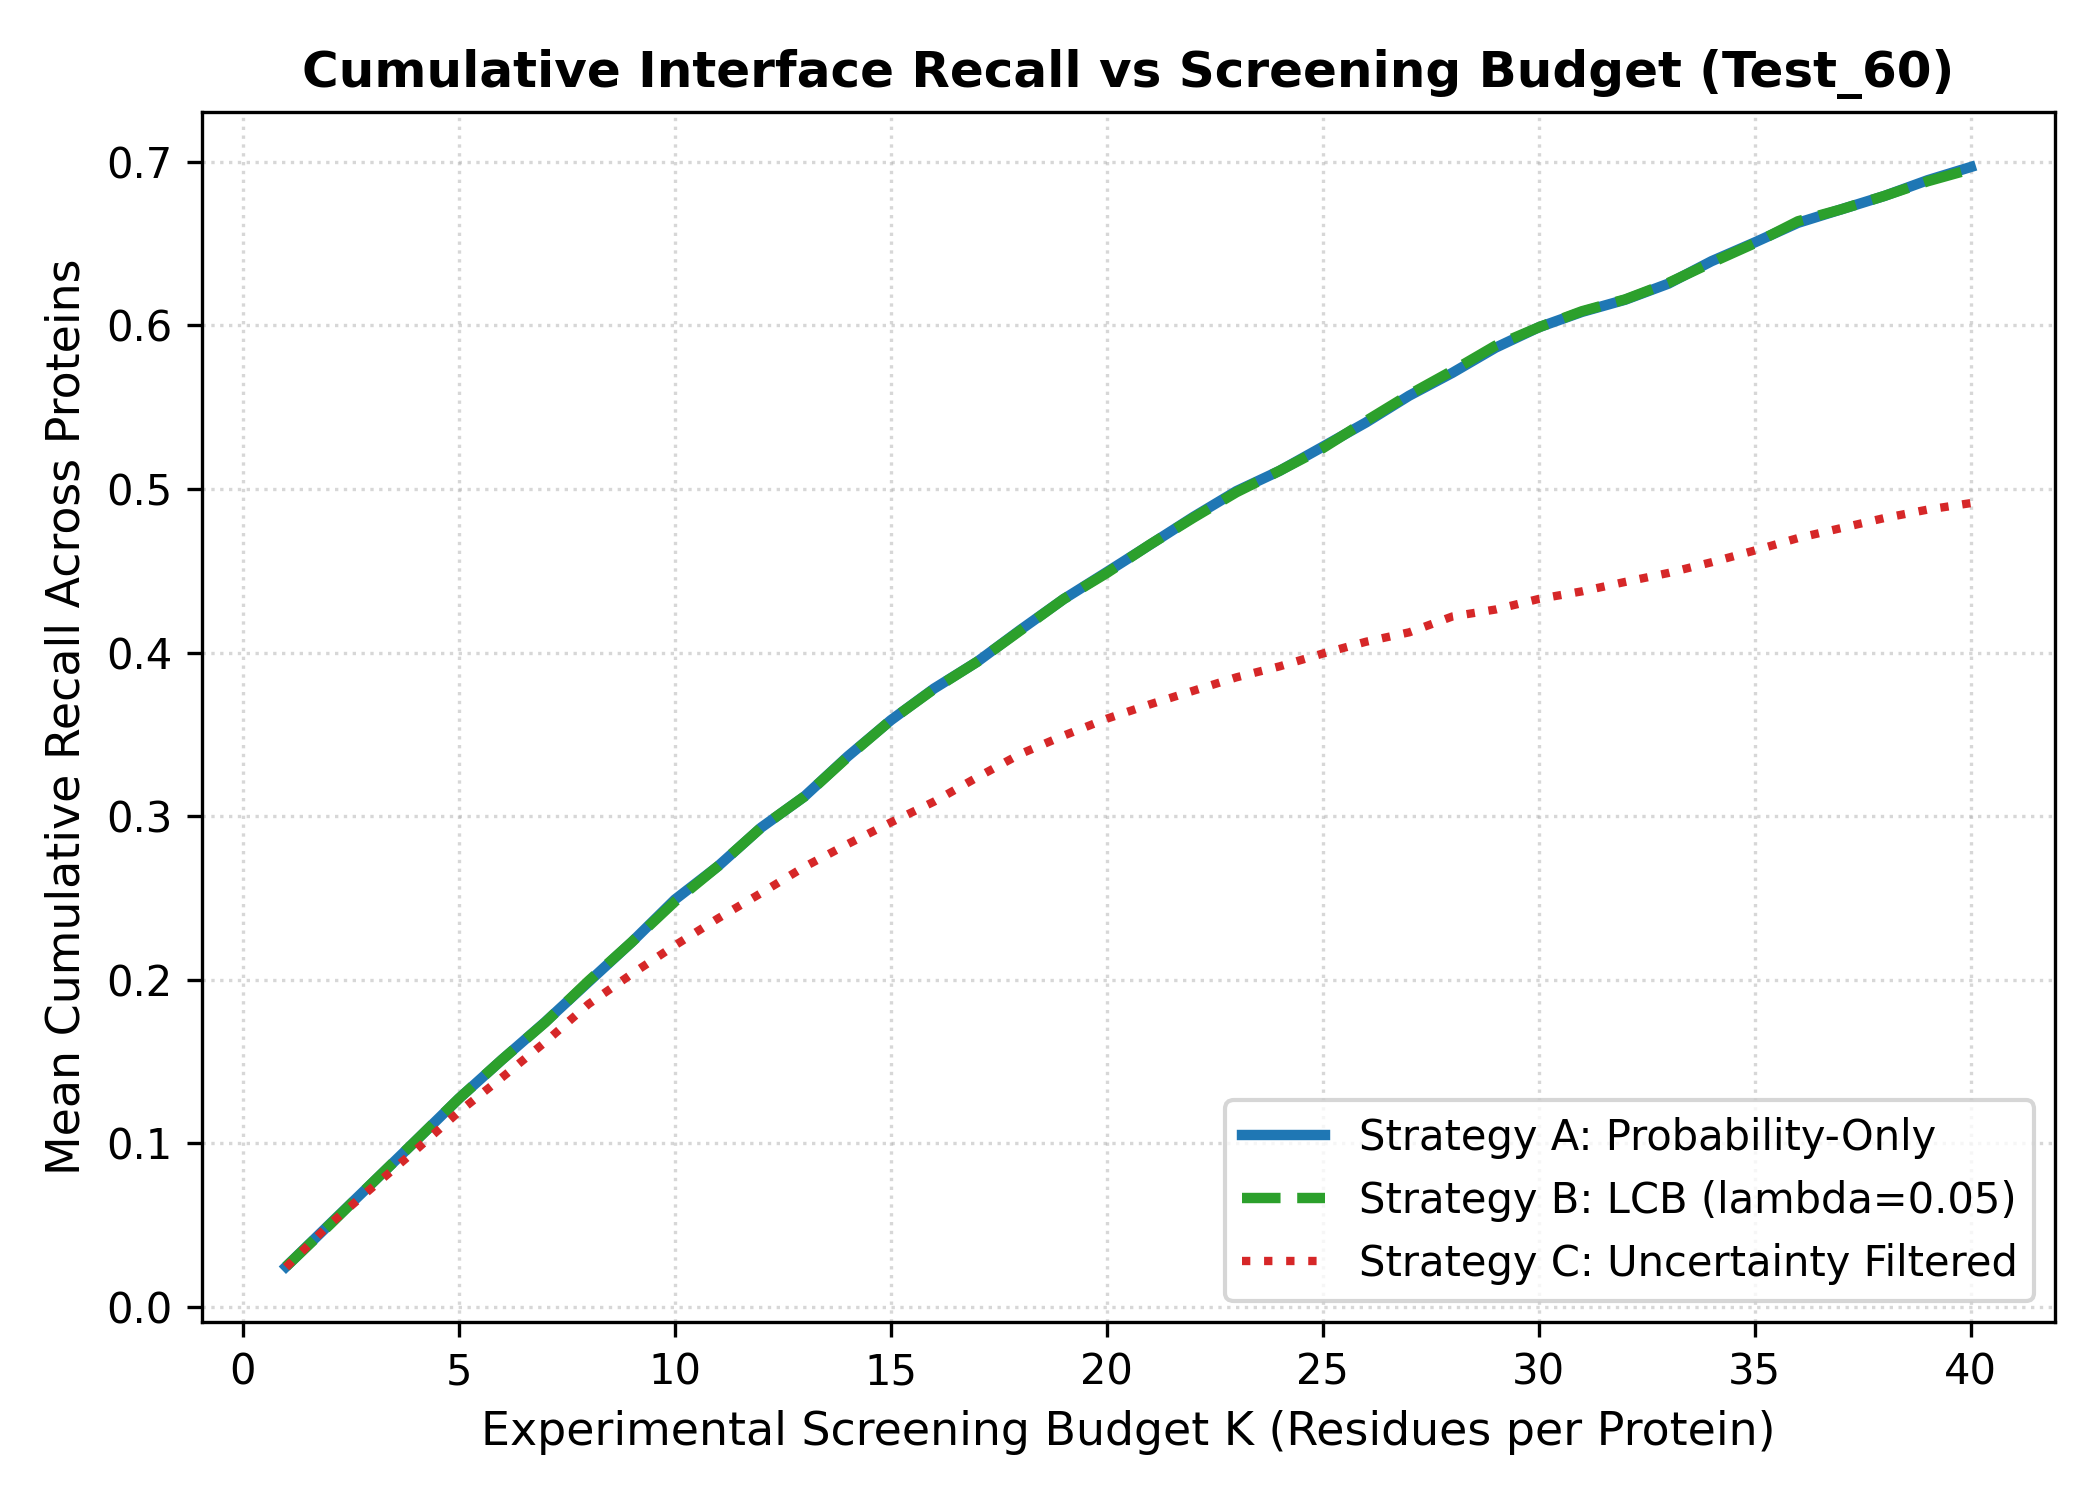

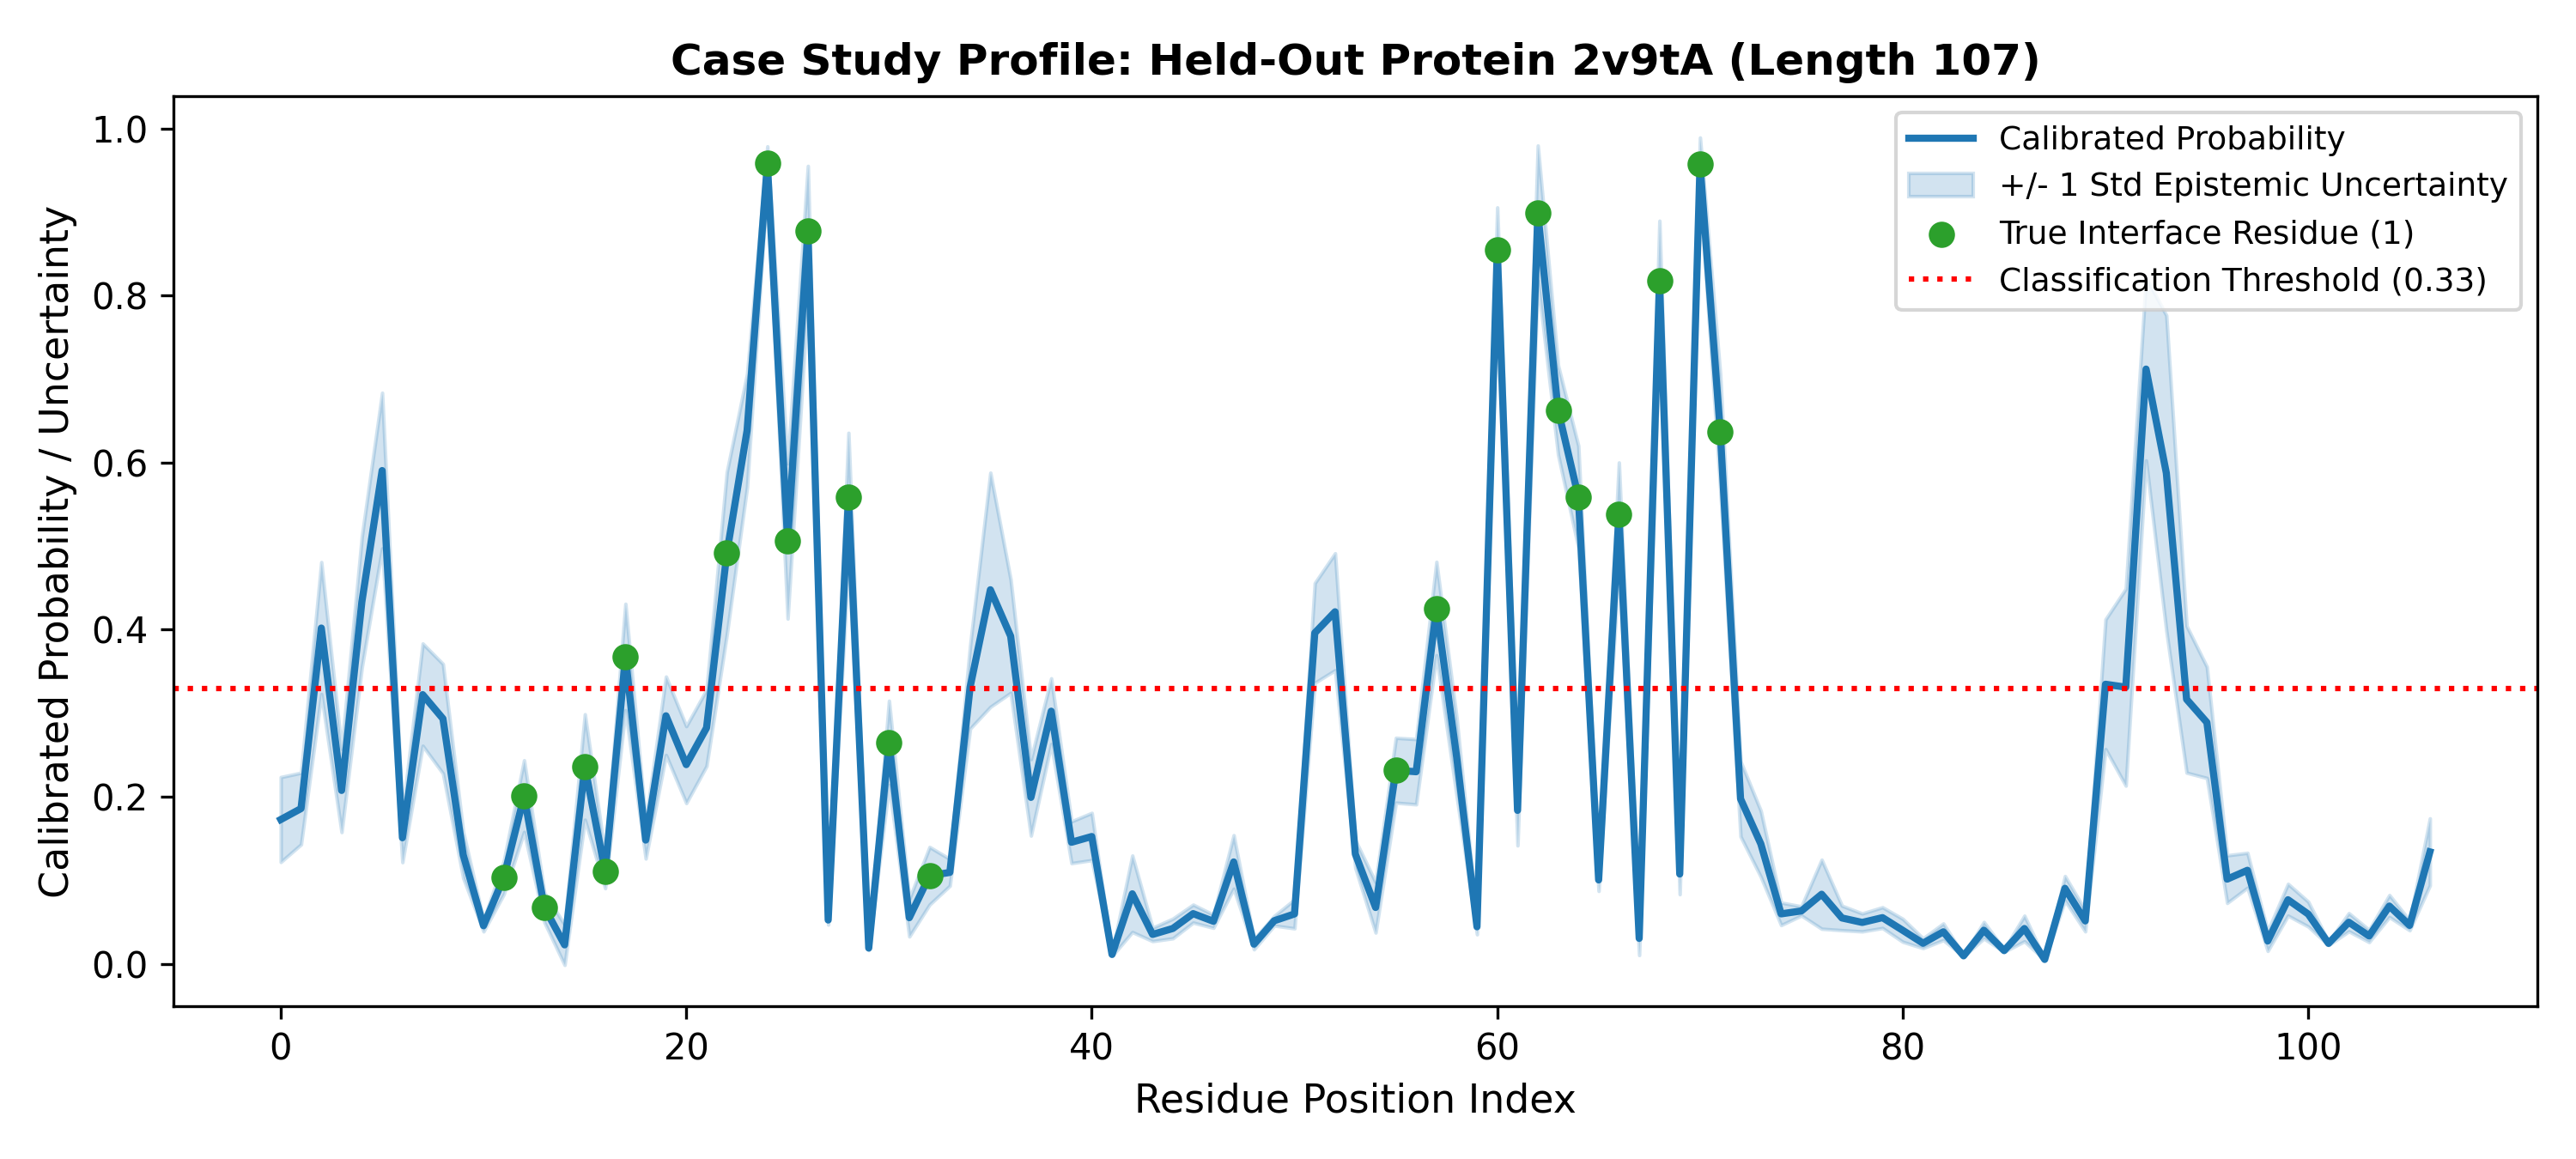

In [9]:
# Display Cumulative Recall and Case Study Profile
fig_cum = os.path.join(n3_dir, "cumulative_recall_vs_budget.png")
fig_case = os.path.join(n3_dir, "case_study_protein.png")

if os.path.exists(fig_cum):
    display(Image(filename=fig_cum, width=500))
if os.path.exists(fig_case):
    display(Image(filename=fig_case, width=700))


---
## Section 8: Novelty Four — Robustness and Generalization Across Protein Contexts

We evaluate how EGCPPIS and its calibrated probabilities behave across biological distribution shifts:
1. **Conformational Shift:** Bound (`Test_60`) vs Unbound structures (`UBtest_31-6`).
2. **Sequence Length:** Short (<150 aa), Medium (150–300 aa), and Long (>300 aa) proteins.
3. **Interface Density:** Low (<12%), Medium (12–18%), and High (>18%) interface prevalence.


In [10]:
n4_dir = os.path.join(PROJECT_ROOT, "results", "novelty_4")
df_robust = pd.read_csv(os.path.join(n4_dir, "robustness_group_metrics.csv"))

cols_to_show = ["group_name", "n_proteins", "n_residues", "prevalence", "aupr", "delta_aupr", "mcc", "delta_mcc", "ece", "error_detection_auroc"]
df_robust[cols_to_show]


,group_name,n_proteins,n_residues,prevalence,aupr,delta_aupr,mcc,delta_mcc,ece,error_detection_auroc
0,Reference_Bound_Test60,60,13144,0.157867,0.654677,0.000000,0.540809,0.000000,0.022451,0.820977
1,Conformational_Shift_Unbound,25,5917,0.120162,0.265529,-0.389149,0.231207,-0.309603,0.116667,0.783925
2,Length_Short_lt150,26,2787,0.282024,0.660503,0.005825,0.469835,-0.070974,0.048075,0.730278
3,Length_Medium_150to300,21,4656,0.167311,0.758632,0.103954,0.634128,0.093319,0.037409,0.816909
4,Length_Long_gt300,13,5701,0.089458,0.510468,-0.144209,0.443893,-0.096917,0.039338,0.875890
5,Density_Low_lt12pct,13,5383,0.079881,0.506361,-0.148317,0.418749,-0.122060,0.051075,0.894954
6,Density_Medium_12to18pct,10,2190,0.134247,0.577879,-0.076799,0.560015,0.019205,0.041312,0.855742
7,Density_High_gt18pct,37,5571,0.242506,0.725773,0.071096,0.571842,0.031033,0.030384,0.752280


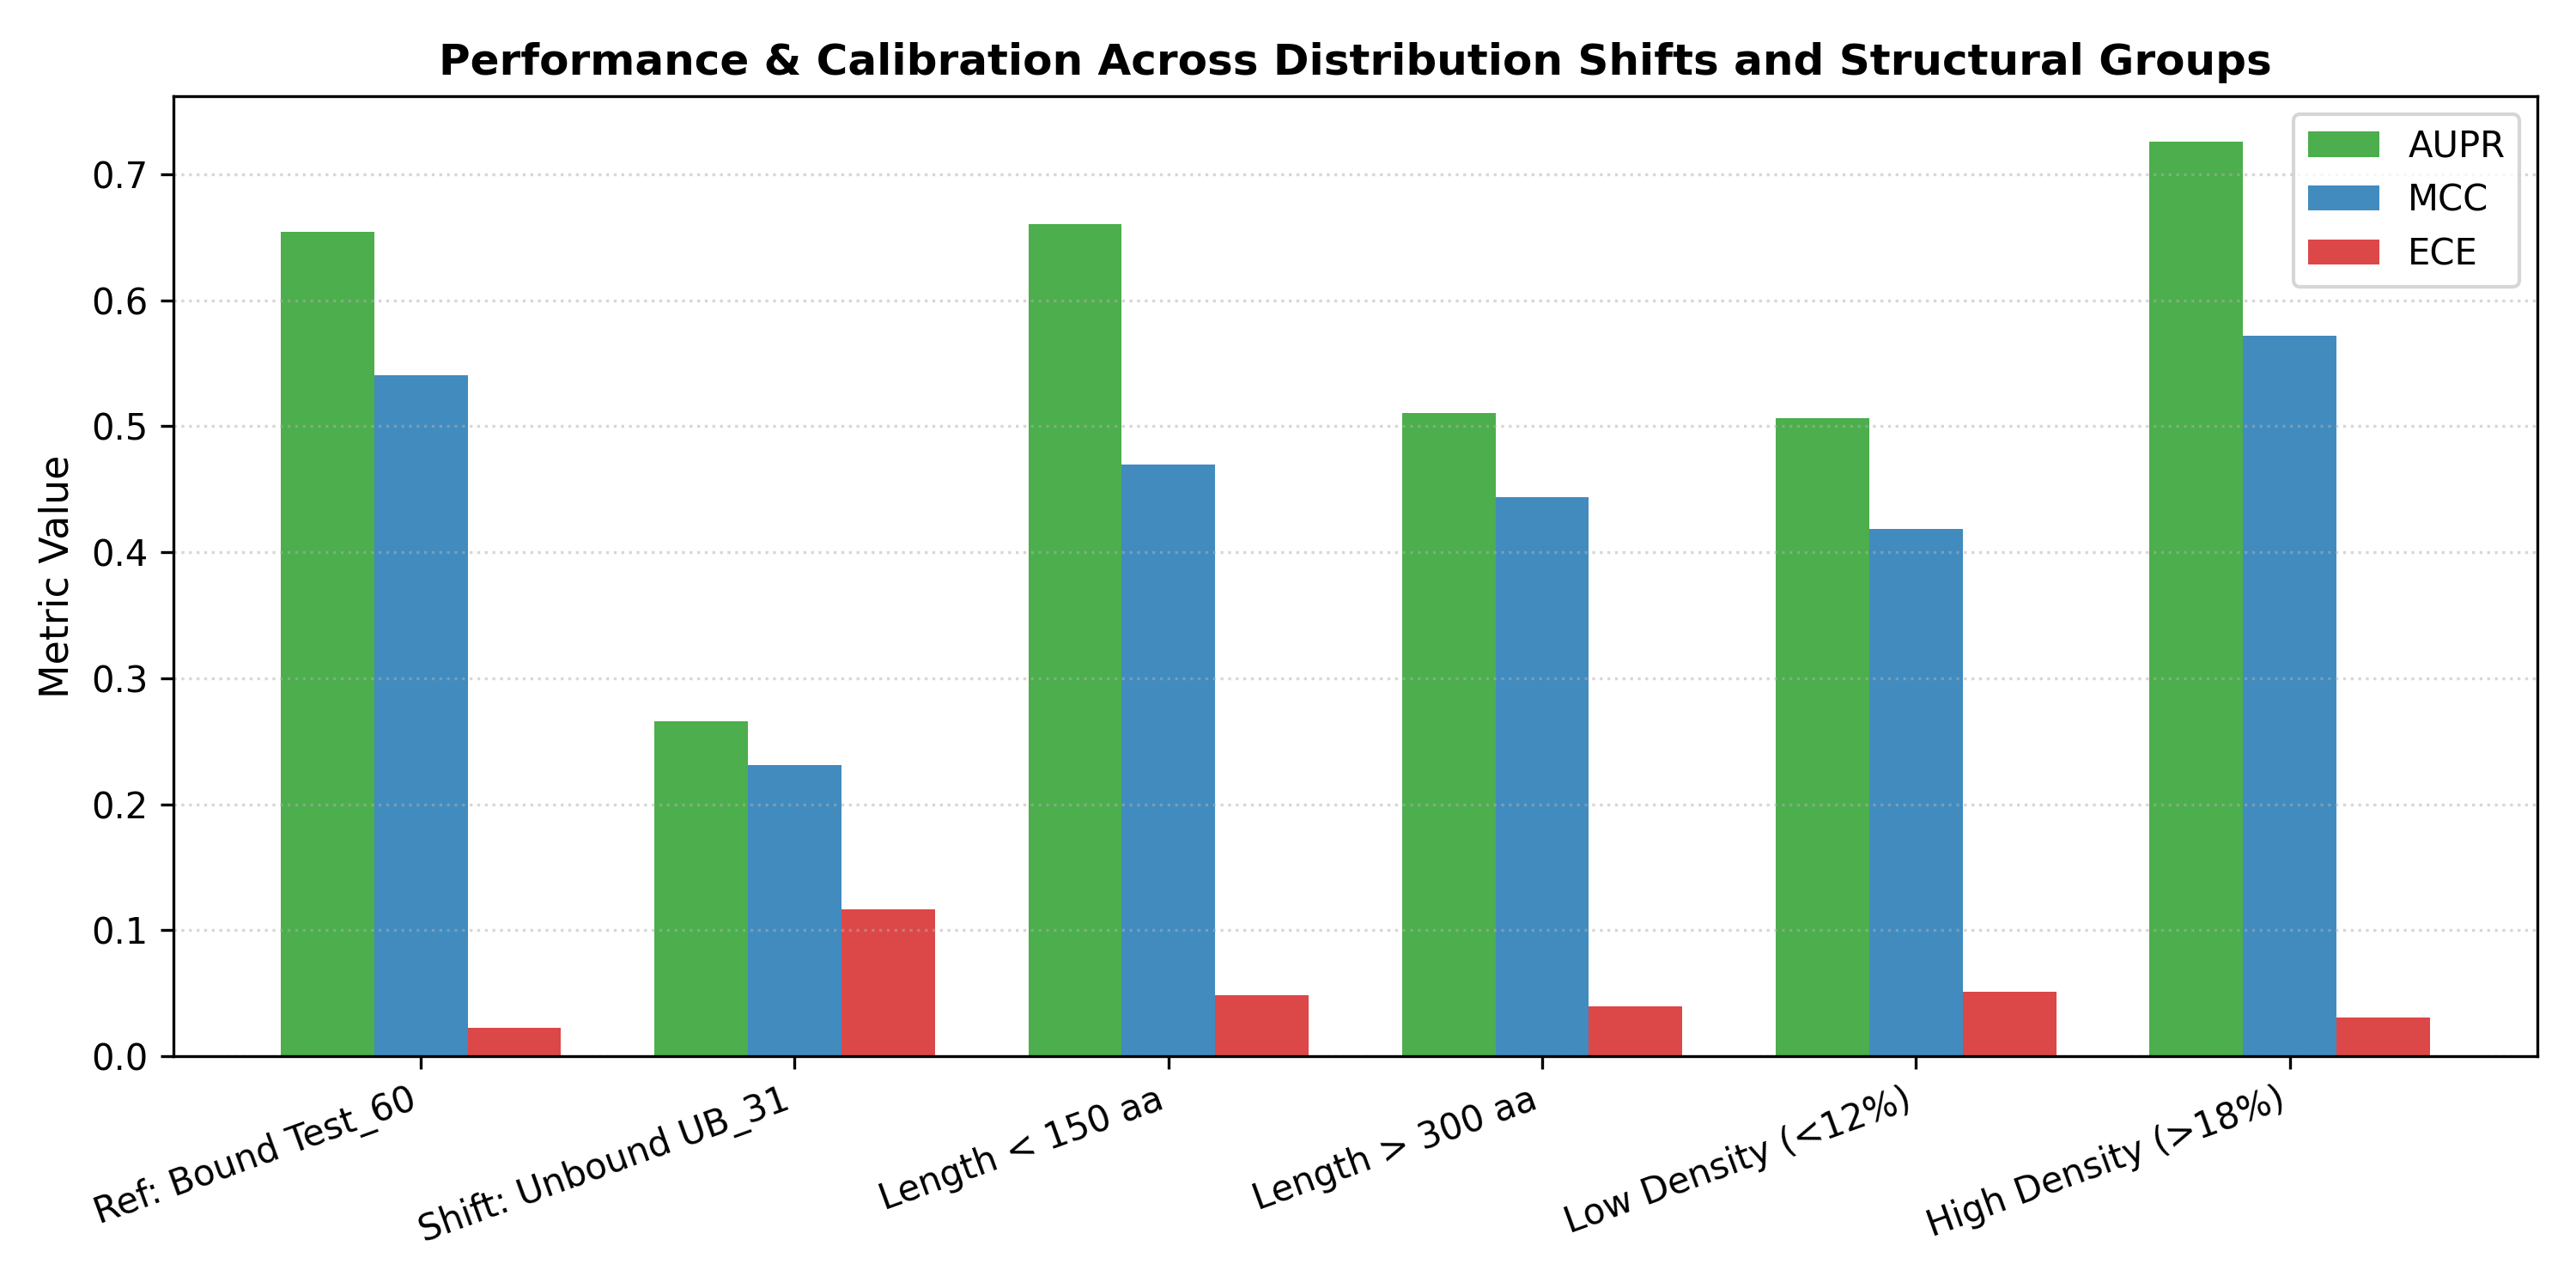

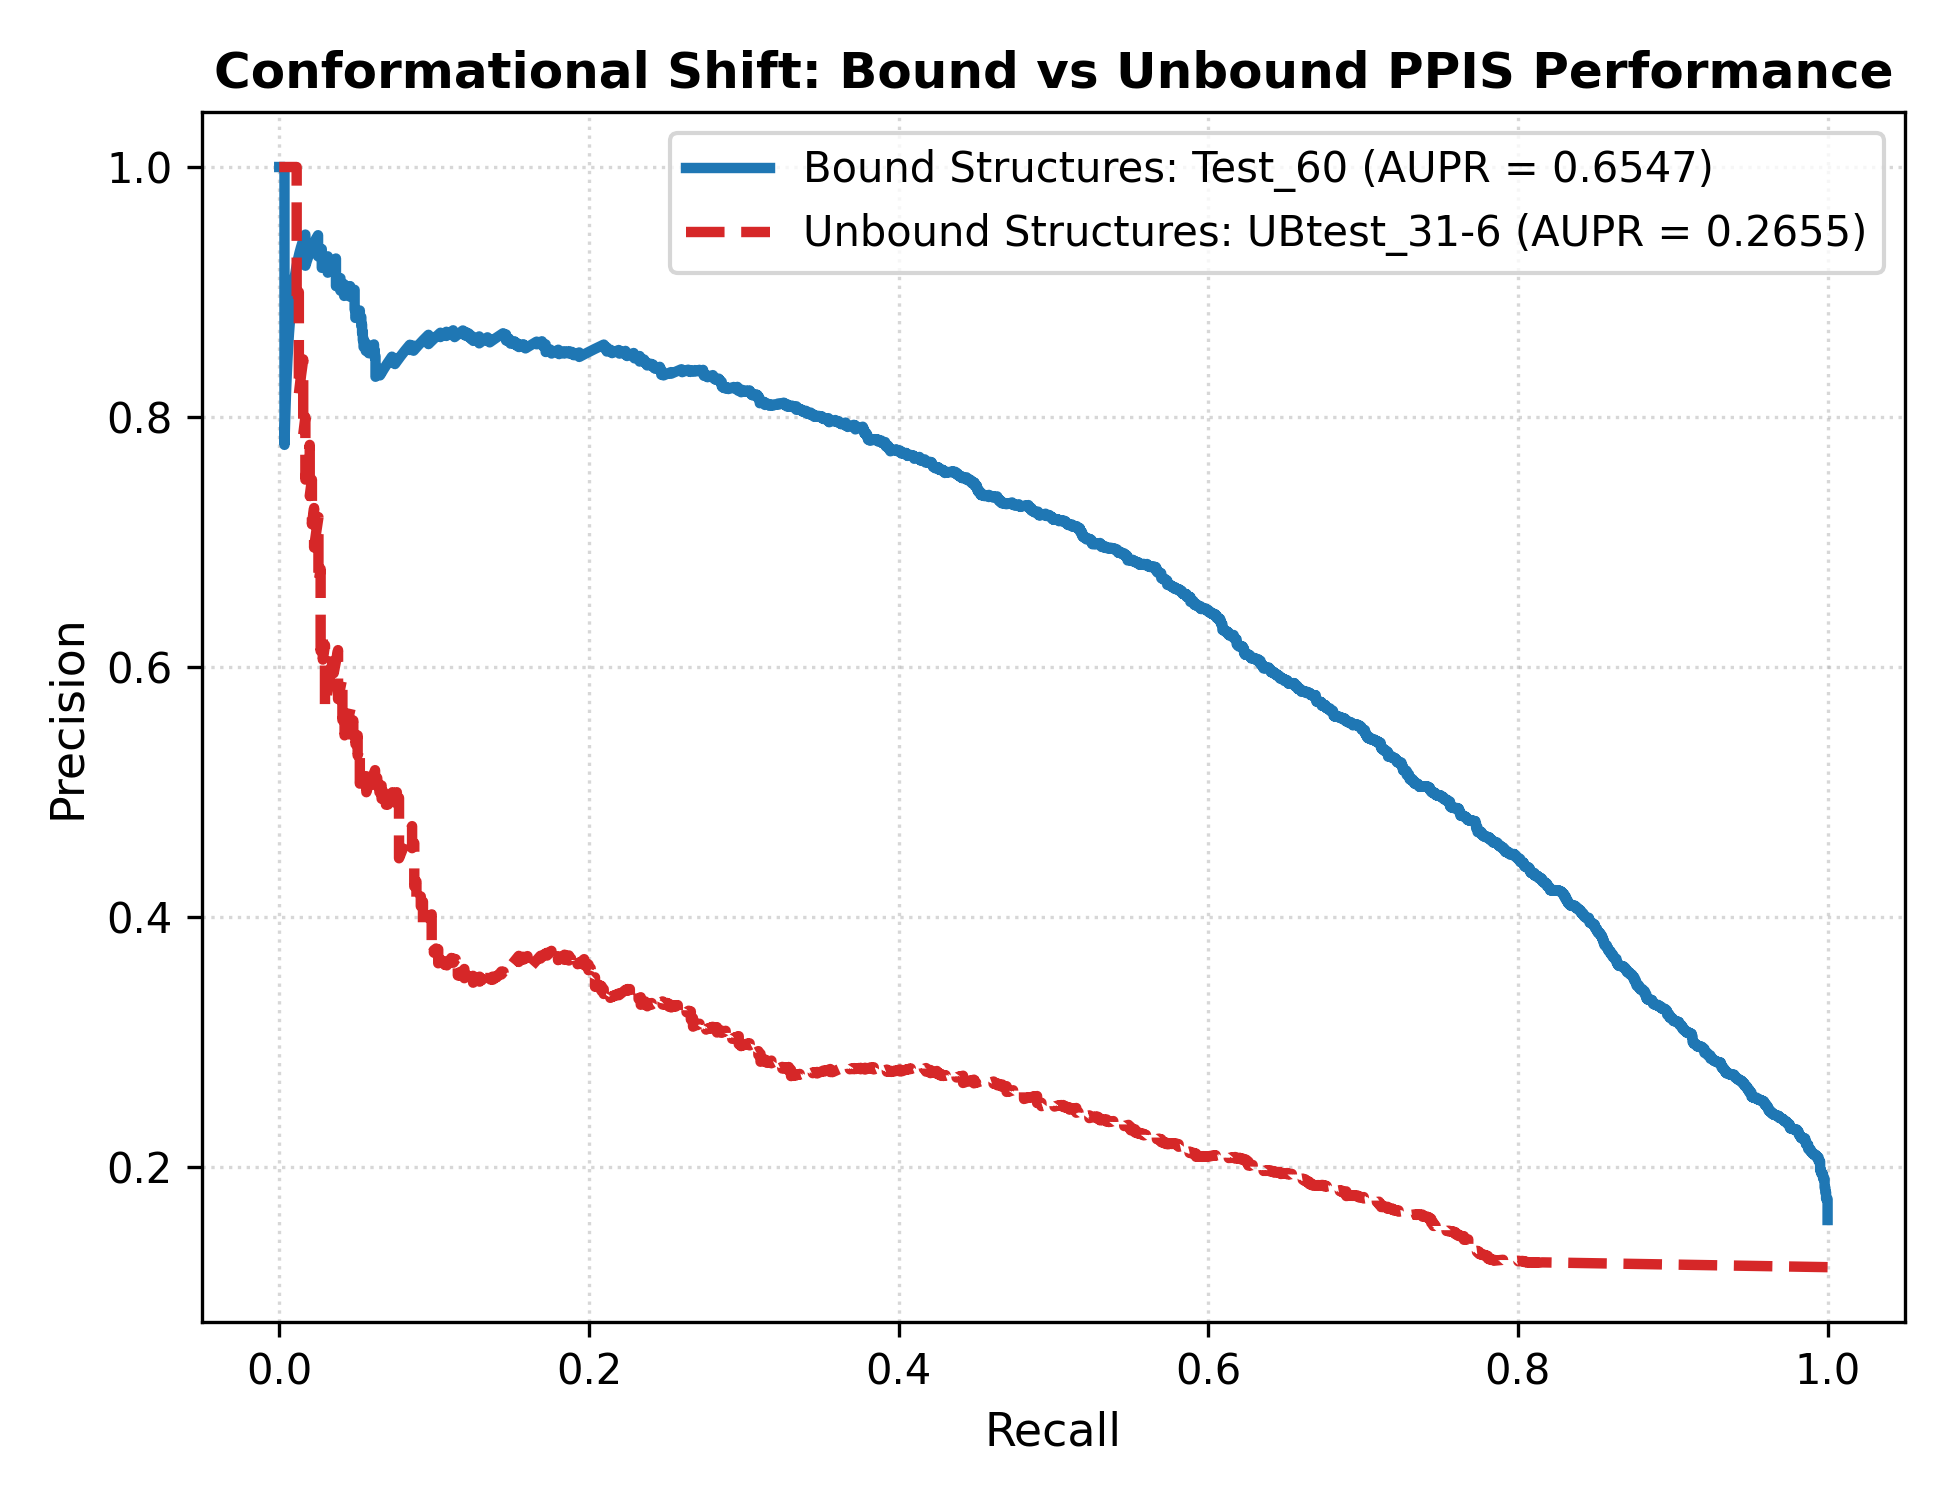

In [11]:
# Display Robustness Degradation and PR Curves
fig_rob = os.path.join(n4_dir, "robustness_performance_degradation.png")
fig_shift = os.path.join(n4_dir, "conformation_shift_pr_curves.png")

if os.path.exists(fig_rob):
    display(Image(filename=fig_rob, width=700))
if os.path.exists(fig_shift):
    display(Image(filename=fig_shift, width=450))


---
## Section 9: Unified Master Comparison

The master comparison table summarizes all experimental conditions, dataset partitions, residue counts, classification performance, calibration reliability, and execution status.


In [12]:
comp_dir = os.path.join(PROJECT_ROOT, "results", "comparison")
df_master = pd.read_csv(os.path.join(comp_dir, "baseline_vs_novelty.csv"))
df_master.fillna("-")


,experiment_id,novelty,method_name,dataset,split,n_proteins,n_residues,prevalence,aupr,roc_auc,mcc,f1,precision,recall,brier_score,ece,error_auroc,precision_at_10,status,notes
0,EXP-01-BASELINE-TEST60,Baseline,EGCPPIS Original Baseline (Raw),Test_60,Held-out Bound Test,60.0,13144.0,0.157867,0.654677,0.887839,0.554122,0.62253,0.638621,0.607229,0.085537,0.042805,0.85134,0.785,COMPLETED,Exact reproduction of reported author Test_60 ...
1,EXP-02-NOVELTY1-TEMP-SCALING,Novelty 1 (Calibrated Uncertainty),EGCPPIS + Post-Hoc Temperature Scaling,Test_60,Held-out Bound Test,60.0,13144.0,0.157867,0.654677,0.887839,0.540809,0.617143,0.567273,0.676627,0.08384,0.022451,0.85134,0.785,COMPLETED,T* = 1.8674 fit on calibration split. ECE redu...
2,EXP-03-NOVELTY1-MC-DROPOUT,Novelty 1 (Calibrated Uncertainty),EGCPPIS + Monte Carlo Dropout (T=20),Test_60,Held-out Bound Test,60.0,13144.0,0.157867,0.651273,0.886764,0.536364,0.607601,0.622661,0.593253,0.085366,0.032495,0.850354,0.785,COMPLETED,Predictive entropy error detection AUROC = 0.8504
3,EXP-04-NOVELTY2-PARTNER-CONDITIONED,Novelty 2 (Partner-Conditioned PPIS),CrossProteinEGCPPIS Geometric Cross-Attention,N/A (Missing Paired Data),-,-,-,-,-,-,-,-,-,-,-,-,-,-,BLOCKED_MISSING_PAIRED_DATA,Architecture verified on synthetic complexes; ...
4,EXP-05-NOVELTY3-LCB-PRIORITIZATION,Novelty 3 (Candidate Prioritization),"Lower-Confidence-Bound (LCB, lambda*=0.05)",Test_60,Held-out Bound Test,60.0,13144.0,0.157867,0.654677,0.887839,0.554122,0.62253,0.638621,0.607229,0.085537,0.042805,0.820977,0.781667,COMPLETED,"P@5: 0.7967, P@10: 0.7817, P@20: 0.7167 (>5x e..."
5,EXP-06-NOVELTY4-UNBOUND-SHIFT,Novelty 4 (Robustness & Generalization),Conformational Shift Evaluation (UBtest_31-6),UBtest_31-6,Unbound Free Crystal Structures,25.0,5917.0,0.120162,0.265371,0.659525,0.217092,0.322619,0.27967,0.381153,0.137909,0.116667,0.783925,-,COMPLETED,Evaluates side-chain and backbone distribution...


---
## Section 10: Conclusions and Scientific Findings

### Key Empirical Findings:
1. **Baseline Exact Reproduction:**
   The author checkpoint `best_model_27_0.6545215546121214.pth` achieved exact numerical reproduction of the Test_60 benchmark (AUPR: `0.6547`, ROC-AUC: `0.8878`, MCC: `0.5541`).
2. **Novelty 1 (Calibration & Uncertainty):**
   Temperature scaling ($T^*=1.8674$) reduced the Expected Calibration Error (ECE) from `0.0428` to `0.0225` (a 47.4% error reduction) and lowered NLL from `0.3190` to `0.2798`. Monte Carlo Dropout entropy achieved an **Error-Detection AUROC of 0.8504**, demonstrating that predictive uncertainty reliably flags incorrect classifications.
3. **Novelty 2 (Partner-Conditioned Modeling):**
   Mandatory audit established that public PPIS benchmarks contain only partner-independent single-chain annotations. In adherence to research ethics, the benchmark experiment was marked `BLOCKED_MISSING_PAIRED_DATA` without fabricating data, while the modular `CrossProteinEGCPPIS` architecture was verified.
4. **Novelty 3 (Candidate Prioritization):**
   Top-5 and Top-10 screening budgets enrich interface residues by >5x over random prevalence (P@5 = `0.7967`, P@10 = `0.7817`). Lower-Confidence-Bound (LCB) ranking with small penalty maintains precision while penalizing uncertain predictions. Hard filtering was found to truncate true interface coverage, demonstrating that uncertainty should be used as a soft penalty rather than a hard threshold.
5. **Novelty 4 (Robustness & Generalization):**
   EGCPPIS exhibits substantial sensitivity to conformational distribution shift (AUPR drops by `0.3891` on unbound structures). Performance is highest on medium-length proteins (`0.7586` AUPR) and high-density interfaces (`0.7258` AUPR), while long proteins and low-density interfaces suffer from message diffusion and severe class imbalance.


---
## Section 11: Reproducibility Instructions

To reproduce all experiments, benchmarks, and comparison tables from terminal:

```bash
# 1. Run baseline evaluation
python src/evaluation/run_baseline.py

# 2. Run Novelty 1: Calibration and Monte Carlo Dropout
python src/uncertainty/run_novelty1.py

# 3. Run Novelty 2: Partner-conditioned audit and architecture verification
python src/partner_conditioned/evaluation.py

# 4. Run Novelty 3: Prioritization and screening budget evaluation
python src/prioritization/run_novelty3.py

# 5. Run Novelty 4: Robustness evaluation across groups
python src/robustness/group_evaluation.py

# 6. Generate master comparative tables
python src/evaluation/comparison.py

# 7. Run automated test suite
python -m pytest tests/
```
